In [32]:
%pip install tensorflow numpy pandas matplotlib seaborn scikit-learn pillow certifi streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
# ==========================================
# IMPORT LIBRARY
# KLASIFIKASI IMAGE OCEANICLIFE MENGGUNAKAN CNN
# ==========================================

# Library dasar
import os
import json
import time
import math
import random

# Pengolahan data
import numpy as np
import pandas as pd

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Pengolahan gambar
from PIL import Image

# Deep Learning
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

# Callback training
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Evaluasi model
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# ==========================================
# CEK VERSI DAN PERANGKAT
# ==========================================

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

print("\nSemua library berhasil di-import!")

TensorFlow Version: 2.21.0
NumPy Version: 2.3.4
Pandas Version: 2.3.3
GPU Available: []

Semua library berhasil di-import!


In [34]:
# ==========================================
# KONFIGURASI PERANGKAT
# ==========================================

# Menggunakan CPU
tf.config.set_visible_devices([], 'GPU')

print("Perangkat yang digunakan: CPU")
print("CPU Available:", tf.config.list_physical_devices('CPU'))

Perangkat yang digunakan: CPU
CPU Available: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [39]:
# ==========================================
# KONFIGURASI DATASET OCEANICLIFE
# ==========================================

BASE_DIR = r"C:\Users\User\OneDrive\Documents\Klasifikasi Image Menggunakan CNN\OceanicLife Dataset"

IMG_SIZE = (160, 160)      # bobot ImageNet MobileNetV2 tersedia untuk 96/128/160/192/224
BATCH_SIZE = 32

EPOCHS = 15                # fase 1: latih "kepala" klasifikasi
FINE_TUNE_EPOCHS = 5       # fase 2: fine-tune sebentar

SEED = 42
WEIGHTS = "imagenet"       # isi None jika tidak bisa mengunduh bobot (akurasi akan lebih rendah)

OUT_DIR = "output_oceaniclife"

os.makedirs(OUT_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)

analysis = {}   # teks analisis otomatis -> dibaca dashboard Streamlit

if not os.path.exists(BASE_DIR):
    raise FileNotFoundError(
        f"Folder dataset tidak ditemukan: {BASE_DIR}"
    )

print("Dataset ditemukan:", BASE_DIR)

# Mengambil semua file gambar (termasuk sub-folder, folder output diabaikan)
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")
out_abs = os.path.abspath(OUT_DIR)

image_paths = []
for root, _, files in os.walk(BASE_DIR):
    if os.path.abspath(root).startswith(out_abs):
        continue
    for f in files:
        if f.lower().endswith(image_extensions):
            image_paths.append(os.path.join(root, f))
image_paths = sorted(image_paths)

print("Total gambar:", len(image_paths))
if not image_paths:
    raise RuntimeError("Tidak ada gambar (jpg/jpeg/png/bmp/gif) di BASE_DIR. Periksa path dataset.")

Dataset ditemukan: C:\Users\User\OneDrive\Documents\Klasifikasi Image Menggunakan CNN\OceanicLife Dataset
Total gambar: 7990


In [40]:
# ==========================================
# MENENTUKAN KELAS DATASET
# ==========================================

class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

class_to_index = {name: index for index, name in enumerate(class_names)}
index_to_class = {index: name for name, index in class_to_index.items()}

NUM_CLASSES = len(class_names)

print("Jumlah kelas:", NUM_CLASSES)

print("\nDaftar kelas:")
for name, index in class_to_index.items():
    print(f"{index} = {name}")

with open(os.path.join(OUT_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)

Jumlah kelas: 8

Daftar kelas:
0 = Fish
1 = Coral
2 = Shark
3 = Octopuses
4 = Crustaceans
5 = Seaweed
6 = Sponges
7 = Other marine organisms


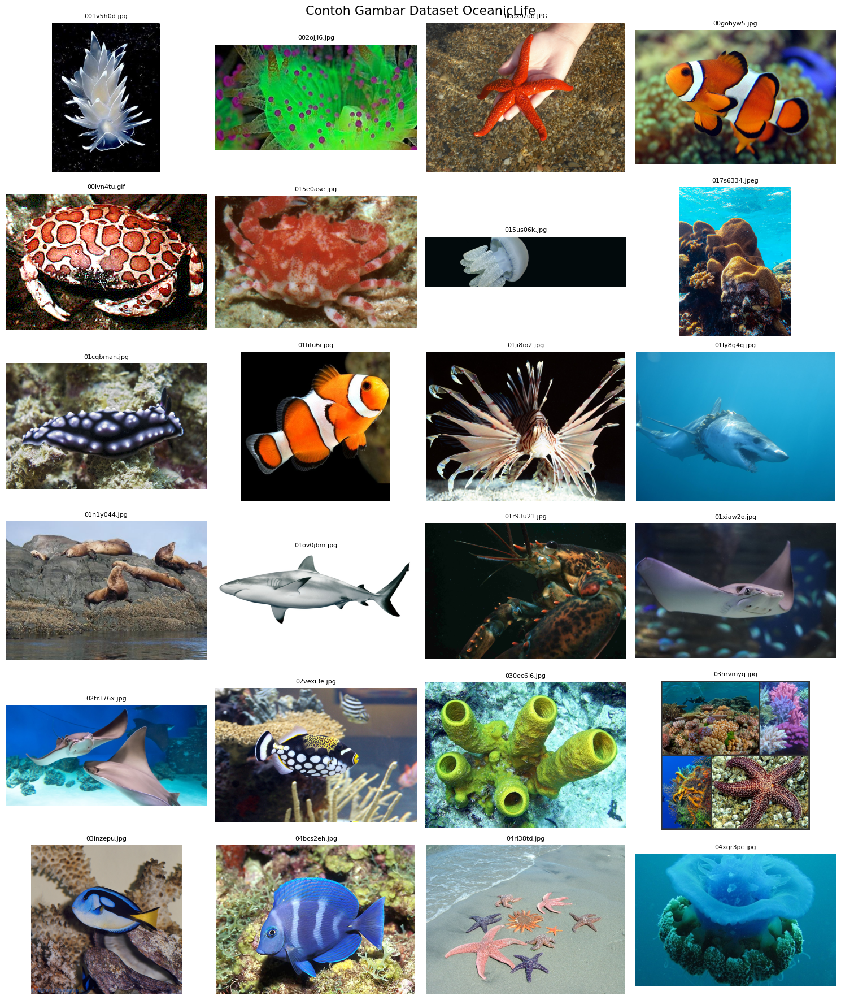

In [41]:
# ==========================================
# MENAMPILKAN CONTOH DATASET
# ==========================================

sample_paths = image_paths[:24]

rows = math.ceil(len(sample_paths) / 4)

plt.figure(figsize=(15, rows * 3))


for i, path in enumerate(sample_paths):

    try:
        img = Image.open(path).convert("RGB")

        plt.subplot(rows, 4, i + 1)
        plt.imshow(img)
        plt.title(os.path.basename(path), fontsize=8)
        plt.axis("off")

    except Exception as e:
        print("Gagal membaca:", path)

plt.suptitle("Contoh Gambar Dataset OceanicLife", fontsize=16)

plt.tight_layout()
plt.show()

In [42]:
# ==========================================
# PELABELAN GAMBAR SECARA MANUAL
# ==========================================

LABEL_MODE = "batch"       # "batch" = 12 gambar per input | "single" = satu per satu
GRID = 12

try:
    from IPython.display import clear_output
except ImportError:
    clear_output = lambda *a, **k: None

label_file = os.path.join(OUT_DIR, "oceaniclife_labels.csv")


def rel_name(path):
    try:
        return os.path.relpath(path, BASE_DIR)
    except ValueError:
        return os.path.basename(path)


# Jika CSV sudah pernah dibuat, lanjutkan gambar yang belum diberi label.
if os.path.exists(label_file):
    labels_df = pd.read_csv(label_file)
    if "filename" not in labels_df.columns:
        labels_df["filename"] = labels_df["filepath"].apply(rel_name)
else:
    labels_df = pd.DataFrame(columns=["filepath", "filename", "label", "label_id"])

labeled_files = set(labels_df["filename"].tolist())
todo = [p for p in image_paths if rel_name(p) not in labeled_files]

print("DAFTAR KELAS:")
for index, name in enumerate(class_names):
    print(f"{index} = {name}")

print(f"\nSudah dilabeli : {len(labeled_files)}")
print(f"Belum dilabeli : {len(todo)}\n")

new_rows = []


def add_row(path, label_id):
    if label_id < 0:
        name = "skip"
    else:
        name = index_to_class[label_id]
    new_rows.append({
        "filepath": path, "filename": rel_name(path),
        "label": name, "label_id": label_id
    })


def save_labels():
    global labels_df, new_rows
    if new_rows:
        labels_df = pd.concat([labels_df, pd.DataFrame(new_rows)], ignore_index=True)
        new_rows = []
    labels_df.to_csv(label_file, index=False)


valid_chars = "-" + "".join(str(i) for i in range(NUM_CLASSES))
stop = False

if LABEL_MODE == "batch":

    for start in range(0, len(todo), GRID):
        batch_paths = todo[start:start + GRID]
        n = len(batch_paths)
        cols = 4
        nrows = math.ceil(n / cols)

        clear_output(wait=True)
        plt.figure(figsize=(14, nrows * 3.6))
        for i, path in enumerate(batch_paths):
            try:
                img = Image.open(path).convert("RGB")
            except Exception:
                img = Image.new("RGB", (64, 64), "black")
            plt.subplot(nrows, cols, i + 1)
            plt.imshow(img)
            plt.title(f"[{i + 1}]", fontsize=16, fontweight="bold")
            plt.axis("off")
        plt.tight_layout()
        plt.show()

        print("Kelas: " + " | ".join(f"{i}={nm}" for i, nm in enumerate(class_names)))
        print(f"Gambar {start + 1}-{start + n} dari {len(todo)} yang belum dilabeli")

        while True:
            ans = input(
                f"Label {n} gambar (mis. 003-1770...; '-' = lewati; q = berhenti): "
            ).strip().lower()
            if ans == "q":
                stop = True
                break
            code_str = ans.replace(" ", "").replace(",", "")
            if len(code_str) == n and all(ch in valid_chars for ch in code_str):
                break
            print(f"Input tidak valid: butuh tepat {n} karakter (angka 0-{NUM_CLASSES - 1} atau '-').")

        if stop:
            break

        for path, ch in zip(batch_paths, code_str):
            add_row(path, -1 if ch == "-" else int(ch))
        save_labels()

else:

    for path in todo:

        try:
            img = Image.open(path).convert("RGB")

            clear_output(wait=True)
            plt.figure(figsize=(5, 5))
            plt.imshow(img)
            plt.title(os.path.basename(path))
            plt.axis("off")
            plt.show()

            print("Nama gambar:", os.path.basename(path))

            label_input = input(
                f"Masukkan nomor kelas (0-{NUM_CLASSES - 1}), skip, atau q untuk berhenti: "
            ).strip().lower()

            if label_input == "q":
                break

            if label_input == "skip":
                add_row(path, -1)
                save_labels()
                continue

            if not label_input.isdigit() or int(label_input) not in range(NUM_CLASSES):
                print("Input tidak valid.")
                continue

            add_row(path, int(label_input))
            save_labels()
            print("Label berhasil disimpan:", index_to_class[int(label_input)])

        except Exception as e:
            print("Gagal memproses gambar:", e)

save_labels()

clear_output(wait=True)
print("Proses pelabelan selesai / dihentikan.")
print("Gambar yang sudah dilabeli (tidak termasuk skip):", int((labels_df["label_id"] >= 0).sum()))
print("\nJumlah per kelas:")
print(labels_df[labels_df["label_id"] >= 0]["label"].value_counts().reindex(class_names).fillna(0).astype(int).to_string())

Proses pelabelan selesai / dihentikan.
Gambar yang sudah dilabeli (tidak termasuk skip): 108

Jumlah per kelas:
label
Fish                      46
Coral                      1
Shark                      3
Octopuses                  2
Crustaceans                8
Seaweed                    0
Sponges                    1
Other marine organisms    47


In [43]:
print(labels_df.head())
print(labels_df.shape)

                                            filepath      filename  \
0  C:\Users\User\OneDrive\Documents\Klasifikasi I...  001v5h0d.jpg   
1  C:\Users\User\OneDrive\Documents\Klasifikasi I...  002ojjl6.jpg   
2  C:\Users\User\OneDrive\Documents\Klasifikasi I...  00dx9zud.JPG   
3  C:\Users\User\OneDrive\Documents\Klasifikasi I...  00gohyw5.jpg   
4  C:\Users\User\OneDrive\Documents\Klasifikasi I...  00lvn4tu.gif   

         label  label_id  
0         Fish         0  
1         Fish         0  
2  Crustaceans         4  
3         Fish         0  
4         Fish         0  
(108, 4)


In [44]:
print(labels_df.columns)

Index(['filepath', 'filename', 'label', 'label_id'], dtype='object')


In [45]:
import os
print(os.path.exists("labels.csv"))


False


In [46]:
import os

print(os.getcwd())


c:\Users\User\OneDrive\Documents\Klasifikasi Image Menggunakan CNN


In [47]:
import os

for f in os.listdir():
    print(f)

Klasifikasi_Image_Menggunakan_CNN.ipynb
OceanicLife Dataset
output
output_oceaniclife


In [48]:
import os

print(os.listdir("output"))

[]


In [49]:
print(os.listdir("output_oceaniclife"))

['3_image_properties.png', 'class_names.json', 'oceaniclife_labels.csv']


In [50]:
LABEL_FILE = "output_oceaniclife/labels.csv"

In [51]:
import os

for root, dirs, files in os.walk("."):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

.\output_oceaniclife\oceaniclife_labels.csv


In [52]:
LABEL_FILE = "output_oceaniclife/oceaniclife_labels.csv"


In [53]:
import os
print(os.path.exists("output_oceaniclife/oceaniclife_labels.csv"))


True


In [54]:
import pandas as pd

labels_df = pd.read_csv("output_oceaniclife/oceaniclife_labels.csv")
print(labels_df.head())
print(labels_df.shape)

                                            filepath      filename  \
0  C:\Users\User\OneDrive\Documents\Klasifikasi I...  001v5h0d.jpg   
1  C:\Users\User\OneDrive\Documents\Klasifikasi I...  002ojjl6.jpg   
2  C:\Users\User\OneDrive\Documents\Klasifikasi I...  00dx9zud.JPG   
3  C:\Users\User\OneDrive\Documents\Klasifikasi I...  00gohyw5.jpg   
4  C:\Users\User\OneDrive\Documents\Klasifikasi I...  00lvn4tu.gif   

         label  label_id  
0         Fish         0  
1         Fish         0  
2  Crustaceans         4  
3         Fish         0  
4         Fish         0  
(108, 4)


In [55]:
print("Jumlah image_paths :", len(image_paths))
print("Jumlah label CSV   :", len(labels_df))
print("Jumlah todo        :", len(todo))

print("\nContoh filename di CSV:")
print(labels_df["filename"].head().tolist())

print("\nContoh rel_name(image_paths):")
print([rel_name(p) for p in image_paths[:5]])

Jumlah image_paths : 7990
Jumlah label CSV   : 108
Jumlah todo        : 7942

Contoh filename di CSV:
['001v5h0d.jpg', '002ojjl6.jpg', '00dx9zud.JPG', '00gohyw5.jpg', '00lvn4tu.gif']

Contoh rel_name(image_paths):
['001v5h0d.jpg', '002ojjl6.jpg', '00dx9zud.JPG', '00gohyw5.jpg', '00lvn4tu.gif']


In [56]:
from collections import Counter

names = [rel_name(p) for p in image_paths]
dup = Counter(names)

duplicates = {k: v for k, v in dup.items() if v > 1}

print("Jumlah nama file yang duplikat:", len(duplicates))

for i, (k, v) in enumerate(duplicates.items()):
    print(k, v)
    if i == 20:
        break

Jumlah nama file yang duplikat: 0


In [57]:
print("image_paths:", len(image_paths))
print("labeled_files:", len(labeled_files))
print("todo:", len(todo))

# Berapa file yang benar-benar cocok?
match = sum(rel_name(p) in labeled_files for p in image_paths)
print("Jumlah file yang cocok:", match)

print("Perhitungan seharusnya:", len(image_paths) - match)

image_paths: 7990
labeled_files: 48
todo: 7942
Jumlah file yang cocok: 48
Perhitungan seharusnya: 7942


In [58]:
print("Total baris:", len(labels_df))
print("Filename unik:", labels_df["filename"].nunique())

duplikat = labels_df[labels_df.duplicated("filename", keep=False)]
print(duplikat.sort_values("filename"))

Total baris: 108
Filename unik: 108
Empty DataFrame
Columns: [filepath, filename, label, label_id]
Index: []


In [59]:
# ==========================================
# PELABELAN GAMBAR SECARA MANUAL
# ==========================================

LABEL_MODE = "batch"       # "batch" = 12 gambar per input | "single" = satu per satu
GRID = 12

try:
    from IPython.display import clear_output
except ImportError:
    clear_output = lambda *a, **k: None

label_file = os.path.join(OUT_DIR, "oceaniclife_labels.csv")


def rel_name(path):
    try:
        return os.path.relpath(path, BASE_DIR)
    except ValueError:
        return os.path.basename(path)


# Jika CSV sudah pernah dibuat, lanjutkan gambar yang belum diberi label.
if os.path.exists(label_file):
    labels_df = pd.read_csv(label_file)

    # Memastikan kolom yang dibutuhkan tersedia
    if "filename" not in labels_df.columns and "filepath" in labels_df.columns:
        labels_df["filename"] = labels_df["filepath"].apply(rel_name)

    if "filepath" not in labels_df.columns:
        labels_df["filepath"] = labels_df["filename"].apply(
            lambda f: os.path.join(BASE_DIR, f)
        )

    if "label" not in labels_df.columns:
        labels_df["label"] = labels_df["label_id"].map(
            lambda x: "skip" if x < 0 else index_to_class[int(x)]
        )

else:
    labels_df = pd.DataFrame(
        columns=["filepath", "filename", "label", "label_id"]
    )

labeled_files = set(labels_df["filename"].tolist())
todo = [p for p in image_paths if rel_name(p) not in labeled_files]

print("DAFTAR KELAS:")
for index, name in enumerate(class_names):
    print(f"{index} = {name}")

print(f"\nSudah dilabeli : {len(labeled_files)}")
print(f"Belum dilabeli : {len(todo)}\n")

new_rows = []


def add_row(path, label_id):
    if label_id < 0:
        name = "skip"
    else:
        name = index_to_class[label_id]
    new_rows.append({
        "filepath": path, "filename": rel_name(path),
        "label": name, "label_id": label_id
    })


def save_labels():
    global labels_df, new_rows
    if new_rows:
        labels_df = pd.concat([labels_df, pd.DataFrame(new_rows)], ignore_index=True)
        new_rows = []
    labels_df.to_csv(label_file, index=False)


valid_chars = "-" + "".join(str(i) for i in range(NUM_CLASSES))
stop = False

if LABEL_MODE == "batch":

    for start in range(0, len(todo), GRID):
        batch_paths = todo[start:start + GRID]
        n = len(batch_paths)
        cols = 4
        nrows = math.ceil(n / cols)

        clear_output(wait=True)
        plt.figure(figsize=(14, nrows * 3.6))
        for i, path in enumerate(batch_paths):
            try:
                img = Image.open(path).convert("RGB")
            except Exception:
                img = Image.new("RGB", (64, 64), "black")
            plt.subplot(nrows, cols, i + 1)
            plt.imshow(img)
            plt.title(f"[{i + 1}]", fontsize=16, fontweight="bold")
            plt.axis("off")
        plt.tight_layout()
        plt.show()

        print("Kelas: " + " | ".join(f"{i}={nm}" for i, nm in enumerate(class_names)))
        print(f"Gambar {start + 1}-{start + n} dari {len(todo)} yang belum dilabeli")

        while True:
            ans = input(
                f"Label {n} gambar (mis. 003-1770...; '-' = lewati; q = berhenti): "
            ).strip().lower()
            if ans == "q":
                stop = True
                break
            code_str = ans.replace(" ", "").replace(",", "")
            if len(code_str) == n and all(ch in valid_chars for ch in code_str):
                break
            print(f"Input tidak valid: butuh tepat {n} karakter (angka 0-{NUM_CLASSES - 1} atau '-').")

        if stop:
            break

        for path, ch in zip(batch_paths, code_str):
            add_row(path, -1 if ch == "-" else int(ch))
        save_labels()

else:

    for path in todo:

        try:
            img = Image.open(path).convert("RGB")

            clear_output(wait=True)
            plt.figure(figsize=(5, 5))
            plt.imshow(img)
            plt.title(os.path.basename(path))
            plt.axis("off")
            plt.show()

            print("Nama gambar:", os.path.basename(path))

            label_input = input(
                f"Masukkan nomor kelas (0-{NUM_CLASSES - 1}), skip, atau q untuk berhenti: "
            ).strip().lower()

            if label_input == "q":
                break

            if label_input == "skip":
                add_row(path, -1)
                save_labels()
                continue

            if not label_input.isdigit() or int(label_input) not in range(NUM_CLASSES):
                print("Input tidak valid.")
                continue

            add_row(path, int(label_input))
            save_labels()
            print("Label berhasil disimpan:", index_to_class[int(label_input)])

        except Exception as e:
            print("Gagal memproses gambar:", e)

save_labels()

clear_output(wait=True)
print("Proses pelabelan selesai / dihentikan.")
print("Gambar yang sudah dilabeli (tidak termasuk skip):", int((labels_df["label_id"] >= 0).sum()))
print("\nJumlah per kelas:")
print(labels_df[labels_df["label_id"] >= 0]["label"].value_counts().reindex(class_names).fillna(0).astype(int).to_string())

Proses pelabelan selesai / dihentikan.
Gambar yang sudah dilabeli (tidak termasuk skip): 132

Jumlah per kelas:
label
Fish                      60
Coral                      1
Shark                      3
Octopuses                  2
Crustaceans               10
Seaweed                    0
Sponges                    1
Other marine organisms    55


In [60]:
# Membaca label sebelumnya
if os.path.exists(label_file):
    labels_df = pd.read_csv(label_file)
else:
    labels_df = pd.DataFrame(columns=["filename", "label_id"])

# Mengambil gambar yang sudah dilabeli
sudah_dilabeli = set(
    labels_df.loc[
        labels_df["label_id"] >= 0,
        "filename"
    ]
)

# Mengambil gambar yang belum dilabeli
belum_dilabeli = [
    p for p in image_paths
    if os.path.basename(p) not in sudah_dilabeli
]

print("Sudah dilabeli:", len(sudah_dilabeli))
print("Belum dilabeli:", len(belum_dilabeli))

Sudah dilabeli: 132
Belum dilabeli: 7858


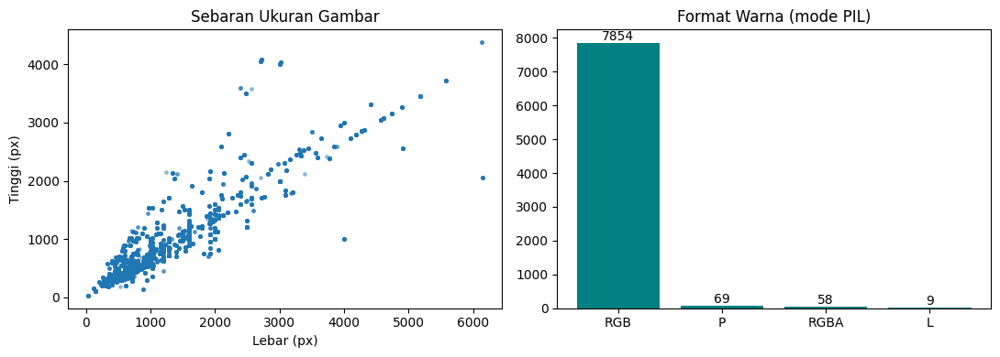

Analisis: Dari 7990 file, lebar rata-rata 1206px (min 32, maks 6144); tinggi rata-rata 879px (min 32, maks 4378). Mode warna: {'RGB': 7854, 'P': 69, 'RGBA': 58, 'L': 9}. File rusak: 0. Karena ukuran tidak seragam dan mode warna bisa bercampur (grayscale/RGBA/palette), semua gambar di-resize ke 160x160 dan dibaca sebagai RGB.


In [61]:
# ---- (a) ukuran gambar, format warna, kualitas (file rusak) -> seluruh dataset
widths, heights, modes, bad = [], [], [], []
for p in image_paths:
    try:
        with Image.open(p) as im:
            w_, h_, m_ = im.size[0], im.size[1], im.mode
            im.verify()
        widths.append(w_); heights.append(h_); modes.append(m_)
    except Exception:
        bad.append(p)

widths, heights = np.array(widths), np.array(heights)
mode_counts = pd.Series(modes).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(widths, heights, s=6, alpha=0.4)
axes[0].set_title("Sebaran Ukuran Gambar"); axes[0].set_xlabel("Lebar (px)"); axes[0].set_ylabel("Tinggi (px)")
b = axes[1].bar(mode_counts.index.astype(str), mode_counts.values, color="teal")
axes[1].bar_label(b)
axes[1].set_title("Format Warna (mode PIL)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "3_image_properties.png"), dpi=120)
plt.show()

if bad:
    print(f"PERINGATAN: {len(bad)} file rusak (otomatis dikeluarkan dari training):")
    print("\n".join(bad[:20]))

analysis["eda_ukuran"] = (
    f"Dari {len(image_paths)} file, lebar rata-rata {widths.mean():.0f}px (min {widths.min()}, maks {widths.max()}); "
    f"tinggi rata-rata {heights.mean():.0f}px (min {heights.min()}, maks {heights.max()}). "
    f"Mode warna: {mode_counts.to_dict()}. File rusak: {len(bad)}. Karena ukuran tidak seragam dan mode warna bisa "
    f"bercampur (grayscale/RGBA/palette), semua gambar di-resize ke {IMG_SIZE[0]}x{IMG_SIZE[1]} dan dibaca sebagai RGB."
)
print("Analisis:", analysis["eda_ukuran"])

In [65]:

# ==========================================
# MEMBACA LABEL DAN MEMERIKSA JUMLAH DATA
# ==========================================

labels_df = pd.read_csv(label_file)

# Memeriksa kolom CSV
print("Kolom CSV:", labels_df.columns.tolist())

# Memastikan kolom yang dibutuhkan tersedia
if not {"filename", "label_id"}.issubset(labels_df.columns):
    raise ValueError("CSV harus memiliki kolom filename dan label_id.")

# Mengambil gambar dengan label valid
df = labels_df[
    pd.to_numeric(labels_df["label_id"], errors="coerce") >= 0
].copy()

# Mengubah label_id menjadi integer
df["label_id"] = df["label_id"].astype(int)

# Membuat lokasi file gambar
df["path"] = df["filename"].apply(
    lambda f: os.path.join(BASE_DIR, str(f))
)

# Memeriksa keberadaan file
df["file_exists"] = df["path"].apply(os.path.exists)

# Menampilkan file yang tidak ditemukan
file_hilang = df[~df["file_exists"]]

print("\nJUMLAH FILE TIDAK DITEMUKAN:", len(file_hilang))

if len(file_hilang) > 0:
    print(file_hilang[["filename", "path"]].head(10))

# Mengambil hanya gambar yang tersedia
df = df[df["file_exists"]].copy()

# Mengubah label ID menjadi nama kelas
df["label"] = df["label_id"].map(index_to_class)

# Menghapus label di luar delapan kelas
df = df[df["label"].isin(class_names)].copy()

# Menghitung jumlah gambar setiap kelas
counts = (
    df["label"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

print("\nTOTAL GAMBAR BERLABEL:", len(df))
print("\nJUMLAH GAMBAR PER KELAS:")
print(counts)

# Memeriksa kelas kosong
kelas_kosong = counts[counts == 0]

# Memeriksa kelas kurang dari 3 gambar
kelas_kurang = counts[counts < 3]

if len(kelas_kosong) > 0:
    print("\nKELAS TANPA GAMBAR:")
    print(kelas_kosong)

if len(kelas_kurang) > 0:
    print("\nKELAS DENGAN GAMBAR KURANG DARI 3:")
    print(kelas_kurang)

    print("\nSilakan periksa dan tambahkan gambar pada kelas tersebut.")

else:
    print("\nSemua kelas sudah memenuhi syarat minimal.")


Kolom CSV: ['filepath', 'filename', 'label', 'label_id']

JUMLAH FILE TIDAK DITEMUKAN: 0

TOTAL GAMBAR BERLABEL: 132

JUMLAH GAMBAR PER KELAS:
label
Fish                      60
Coral                      1
Shark                      3
Octopuses                  2
Crustaceans               10
Seaweed                    0
Sponges                    1
Other marine organisms    55
Name: count, dtype: int64

KELAS TANPA GAMBAR:
label
Seaweed    0
Name: count, dtype: int64

KELAS DENGAN GAMBAR KURANG DARI 3:
label
Coral        1
Octopuses    2
Seaweed      0
Sponges      1
Name: count, dtype: int64

Silakan periksa dan tambahkan gambar pada kelas tersebut.


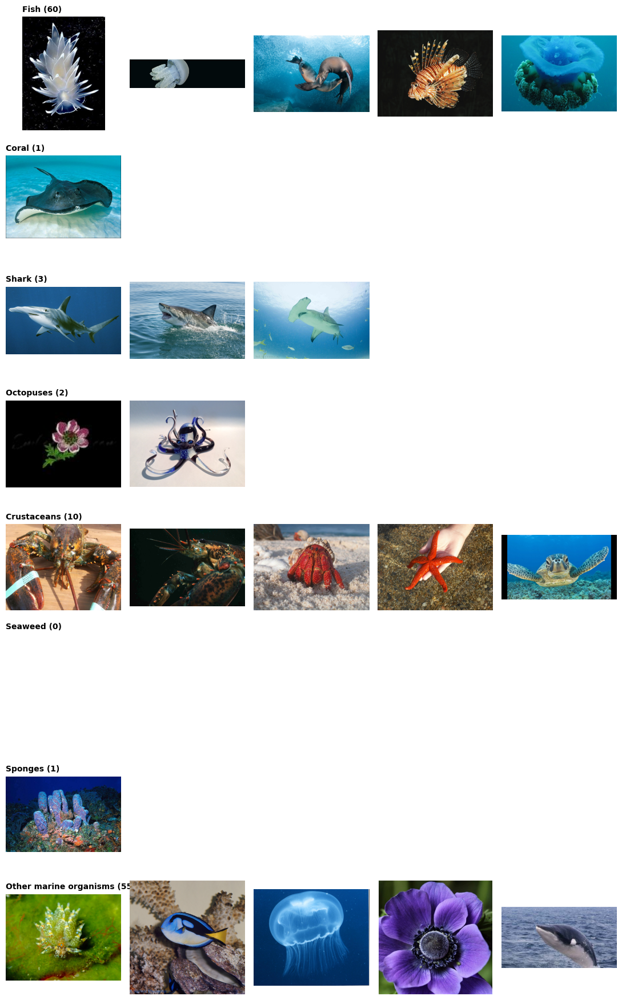

Analisis: Contoh visual tiap kelas menunjukkan variasi sudut pandang, pencahayaan (air laut cenderung kebiruan/kehijauan), latar belakang, dan ukuran objek. Kelas dengan bentuk mirip (mis. Fish vs Shark, Coral vs Sponges) berpotensi saling tertukar, sehingga augmentasi data dipakai untuk menambah variasi. Angka dalam kurung adalah jumlah gambar berlabel.


In [66]:
# ---- (c) contoh gambar tiap kelas
N_EX = 5
fig, axes = plt.subplots(NUM_CLASSES, N_EX, figsize=(2.2 * N_EX, 2.2 * NUM_CLASSES))
for r, c in enumerate(class_names):
    sub = df[df.label == c]
    pick = sub.sample(min(N_EX, len(sub)), random_state=SEED)["path"].tolist() if len(sub) else []
    for k in range(N_EX):
        ax = axes[r, k]
        ax.axis("off")
        if k < len(pick):
            try:
                ax.imshow(Image.open(pick[k]).convert("RGB"))
            except Exception:
                pass
        if k == 0:
            ax.set_title(f"{c} ({len(sub)})", fontsize=10, loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "2_class_examples.png"), dpi=110)
plt.show()

analysis["eda_contoh"] = (
    "Contoh visual tiap kelas menunjukkan variasi sudut pandang, pencahayaan (air laut cenderung kebiruan/kehijauan), "
    "latar belakang, dan ukuran objek. Kelas dengan bentuk mirip (mis. Fish vs Shark, Coral vs Sponges) berpotensi "
    "saling tertukar, sehingga augmentasi data dipakai untuk menambah variasi. Angka dalam kurung adalah jumlah gambar berlabel."
)
print("Analisis:", analysis["eda_contoh"])

In [69]:

print("===== PEMERIKSAAN DATASET =====")

print("Jumlah data:", len(df))
print("Jumlah kelas:", df["label_id"].nunique())
print("NUM_CLASSES:", NUM_CLASSES)

print("\nDistribusi label:")
print(df.groupby(["label_id", "label"]).size())

print("\nPemeriksaan path:")
print("Path kosong:", df["path"].isna().sum())
print("File tidak ditemukan:",
      (~df["path"].apply(os.path.exists)).sum())

print("\nPemeriksaan variabel:")
print("SEED:", SEED)
print("IMG_SIZE:", IMG_SIZE)
print("BATCH_SIZE:", BATCH_SIZE)

print("\n===== SELESAI =====")


===== PEMERIKSAAN DATASET =====
Jumlah data: 132
Jumlah kelas: 7
NUM_CLASSES: 8

Distribusi label:
label_id  label                 
0         Fish                      60
1         Coral                      1
2         Shark                      3
3         Octopuses                  2
4         Crustaceans               10
6         Sponges                    1
7         Other marine organisms    55
dtype: int64

Pemeriksaan path:
Path kosong: 0
File tidak ditemukan: 0

Pemeriksaan variabel:
SEED: 42
IMG_SIZE: (160, 160)
BATCH_SIZE: 32

===== SELESAI =====


In [70]:
class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

NUM_CLASSES = len(class_names)

print("Jumlah kelas:", NUM_CLASSES)

Jumlah kelas: 8


In [71]:
index_to_class = {
    i: name for i, name in enumerate(class_names)
}

In [72]:
print("Distribusi label ID pada CSV:")

print(labels_df["label_id"].value_counts(dropna=False).sort_index())

print("\nData dengan label ID 5:")

print(
    labels_df[labels_df["label_id"] == 5][
        ["filename", "label_id"]
    ]
)

Distribusi label ID pada CSV:
label_id
0    60
1     1
2     3
3     2
4    10
6     1
7    55
Name: count, dtype: int64

Data dengan label ID 5:
Empty DataFrame
Columns: [filename, label_id]
Index: []


In [74]:

import os

print("STRUKTUR FOLDER DATASET")

for root, dirs, files in os.walk(BASE_DIR):
    level = root.replace(BASE_DIR, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")


STRUKTUR FOLDER DATASET
OceanicLife Dataset/
    001v5h0d.jpg
    002ojjl6.jpg
    00dx9zud.JPG
    00gohyw5.jpg
    00lvn4tu.gif


In [75]:
image_paths
labeled_files
todo

['C:\\Users\\User\\OneDrive\\Documents\\Klasifikasi Image Menggunakan CNN\\OceanicLife Dataset\\0j8c5791.jpeg',
 'C:\\Users\\User\\OneDrive\\Documents\\Klasifikasi Image Menggunakan CNN\\OceanicLife Dataset\\0jrhtrjt.jpg',
 'C:\\Users\\User\\OneDrive\\Documents\\Klasifikasi Image Menggunakan CNN\\OceanicLife Dataset\\0keo4cqi.JPG',
 'C:\\Users\\User\\OneDrive\\Documents\\Klasifikasi Image Menggunakan CNN\\OceanicLife Dataset\\0kh0u2c7.jpg',
 'C:\\Users\\User\\OneDrive\\Documents\\Klasifikasi Image Menggunakan CNN\\OceanicLife Dataset\\0khsugib.jpg',
 'C:\\Users\\User\\OneDrive\\Documents\\Klasifikasi Image Menggunakan CNN\\OceanicLife Dataset\\0kmbhxcd.jpg',
 'C:\\Users\\User\\OneDrive\\Documents\\Klasifikasi Image Menggunakan CNN\\OceanicLife Dataset\\0kzcr6b2.jpg',
 'C:\\Users\\User\\OneDrive\\Documents\\Klasifikasi Image Menggunakan CNN\\OceanicLife Dataset\\0l9eliic.jpeg',
 'C:\\Users\\User\\OneDrive\\Documents\\Klasifikasi Image Menggunakan CNN\\OceanicLife Dataset\\0l9v8t4w.jpg',

In [78]:

import os
import pandas as pd
from pathlib import Path

# Lokasi dataset
BASE_DIR = Path(BASE_DIR)

# Lokasi CSV label
label_file = Path(label_file)

# Membaca seluruh gambar
ekstensi = {
    ".jpg", ".jpeg", ".png",
    ".gif", ".bmp", ".webp"
}

image_paths = [
    str(p)
    for p in BASE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in ekstensi
]

# Membaca CSV lama
labels_df = pd.read_csv(label_file)

# Memastikan kolom filename tersedia
if "filename" not in labels_df.columns:
    raise ValueError("Kolom filename tidak ditemukan dalam CSV.")

# Membandingkan nama file
labeled_files = set(
    labels_df["filename"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
)

# Mencari gambar yang belum dilabeli
todo = [
    p for p in image_paths
    if Path(p).name.lower() not in labeled_files
]

print("TOTAL GAMBAR       :", len(image_paths))
print("SUDAH DILABELI     :", len(labeled_files))
print("BELUM DILABELI     :", len(todo))

print("\nCONTOH GAMBAR BELUM DILABELI:")
for p in todo[:10]:
    print(Path(p).name)


TOTAL GAMBAR       : 7990
SUDAH DILABELI     : 132
BELUM DILABELI     : 7858

CONTOH GAMBAR BELUM DILABELI:
0nkq1d90.jpg
0npvao98.jpg
0nw0zd65.jpg
0nw1o02f.jpg
0o00zlph.jpg
0oh0akzo.jpg
0ojtp23m.JPG
0okgwkov.jpg
0olckdkz.JPG
0oqnycte.jpg


In [79]:
%pip install ipywidgets

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:

import os
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image
from pathlib import Path

# ==========================================
# KONFIGURASI
# ==========================================

BASE_DIR = Path(BASE_DIR)
label_file = Path(label_file)

class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

# ==========================================
# MEMBACA CSV LAMA
# ==========================================

if label_file.exists():
    labels_df = pd.read_csv(label_file)
else:
    labels_df = pd.DataFrame(
        columns=["filepath", "filename", "label", "label_id"]
    )

# ==========================================
# MENCARI GAMBAR BELUM DILABELI
# ==========================================

extensions = {
    ".jpg", ".jpeg", ".png",
    ".gif", ".bmp", ".webp"
}

image_paths = [
    str(p) for p in BASE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
]

labeled_files = set(
    labels_df["filename"].dropna().astype(str).str.lower()
)

todo = [
    p for p in image_paths
    if Path(p).name.lower() not in labeled_files
]

print("Total gambar:", len(image_paths))
print("Sudah dilabeli:", len(labeled_files))
print("Belum dilabeli:", len(todo))

# ==========================================
# TAMPILAN PELABELAN
# ==========================================

index = 0

output = widgets.Output()

info = widgets.HTML()

buttons = []

for i, name in enumerate(class_names):
    btn = widgets.Button(
        description=name,
        button_style="",
        layout=widgets.Layout(width="220px")
    )

    buttons.append(btn)

skip_btn = widgets.Button(
    description="Lewati",
    button_style="warning"
)

def show_image():
    global index

    with output:
        clear_output(wait=True)

        if index >= len(todo):
            print("Semua gambar dalam antrean telah diperiksa.")
            return

        path = todo[index]

        print(f"Gambar {index + 1} dari {len(todo)}")
        print(Path(path).name)

        try:
            img = Image.open(path).convert("RGB")
            display(img.resize((500, 350)))
        except Exception as e:
            print("Gambar gagal dibuka:", e)

    info.value = (
        f"<b>Progress:</b> {index + 1} / {len(todo)}"
    )

def save_label(label_id):
    global index, labels_df

    if index >= len(todo):
        return

    path = todo[index]
    filename = Path(path).name

    new_row = pd.DataFrame([{
        "filepath": path,
        "filename": filename,
        "label": class_names[label_id],
        "label_id": label_id
    }])

    labels_df = pd.concat(
        [labels_df, new_row],
        ignore_index=True
    )

    # Simpan setiap gambar
    labels_df.to_csv(label_file, index=False)

    index += 1
    show_image()

def skip_image(_):
    global index
    index += 1
    show_image()

for i, btn in enumerate(buttons):
    btn.on_click(
        lambda b, label_id=i: save_label(label_id)
    )

skip_btn.on_click(skip_image)

show_image()

display(info)
display(widgets.VBox([
    widgets.GridBox(
        buttons,
        layout=widgets.Layout(
            grid_template_columns="repeat(2, 220px)",
            grid_gap="8px"
        )
    ),
    skip_btn,
    output
]))


Total gambar: 7990
Sudah dilabeli: 132
Belum dilabeli: 7858


HTML(value='<b>Progress:</b> 1 / 7858')

In [81]:
import pandas as pd

labels_df = pd.read_csv(label_file)

counts = (
    labels_df["label"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

print("TOTAL GAMBAR BERLABEL:", len(labels_df))

print("\nDISTRIBUSI 8 KELAS:")
print(counts)

print("\nTOTAL KELAS:", len(counts))
print("KELAS KOSONG:", list(counts[counts == 0].index))

TOTAL GAMBAR BERLABEL: 133

DISTRIBUSI 8 KELAS:
label
Fish                      61
Coral                      1
Shark                      3
Octopuses                  2
Crustaceans               10
Seaweed                    0
Sponges                    1
Other marine organisms    55
Name: count, dtype: int64

TOTAL KELAS: 8
KELAS KOSONG: ['Seaweed']


In [82]:

import os
import pandas as pd
import ipywidgets as widgets
from pathlib import Path
from PIL import Image
from IPython.display import display, clear_output

# ==========================================
# KONFIGURASI KELAS
# ==========================================

class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

# Pastikan BASE_DIR dan label_file sudah didefinisikan
BASE_DIR = Path(BASE_DIR)
label_file = Path(label_file)

# ==========================================
# MEMBACA LABEL LAMA
# ==========================================

labels_df = pd.read_csv(label_file)

# ==========================================
# MEMBACA SELURUH GAMBAR
# ==========================================

extensions = {
    ".jpg", ".jpeg", ".png",
    ".gif", ".bmp", ".webp"
}

image_paths = [
    str(p) for p in BASE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
]

# Nama file yang sudah dilabeli
labeled_files = set(
    labels_df["filename"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
)

# Antrean gambar yang belum dilabeli
todo = [
    p for p in image_paths
    if Path(p).name.lower() not in labeled_files
]

print("Total gambar:", len(image_paths))
print("Sudah dilabeli:", len(labeled_files))
print("Belum dilabeli:", len(todo))

# ==========================================
# TAMPILAN PELABELAN
# ==========================================

index = 0

output = widgets.Output()
info = widgets.HTML()

def show_image():
    global index

    with output:
        clear_output(wait=True)

        if index >= len(todo):
            print("Semua gambar dalam antrean selesai!")
            return

        path = todo[index]

        print("Gambar:", index + 1, "/", len(todo))
        print("Filename:", Path(path).name)

        try:
            img = Image.open(path).convert("RGB")
            img.thumbnail((600, 450))
            display(img.copy())
        except Exception as e:
            print("Gagal membuka gambar:", e)

    info.value = (
        f"<b>Progress:</b> {index + 1} / {len(todo)}"
    )

# ==========================================
# MENYIMPAN LABEL
# ==========================================

def save_label(label_id):
    global index, labels_df

    if index >= len(todo):
        return

    path = todo[index]
    filename = Path(path).name

    new_row = pd.DataFrame([{
        "filepath": path,
        "filename": filename,
        "label": class_names[label_id],
        "label_id": label_id
    }])

    labels_df = pd.concat(
        [labels_df, new_row],
        ignore_index=True
    )

    # Simpan langsung ke CSV
    labels_df.to_csv(label_file, index=False)

    index += 1
    show_image()

# ==========================================
# TOMBOL KELAS
# ==========================================

buttons = []

for i, name in enumerate(class_names):

    btn = widgets.Button(
        description=name,
        layout=widgets.Layout(width="220px", height="40px")
    )

    btn.on_click(
        lambda b, label_id=i: save_label(label_id)
    )

    buttons.append(btn)

# Tombol lewati
skip_btn = widgets.Button(
    description="Lewati gambar",
    button_style="warning"
)

def skip_image(b):
    global index
    index += 1
    show_image()

skip_btn.on_click(skip_image)

# ==========================================
# MENAMPILKAN ANTARMUKA
# ==========================================

show_image()

display(info)

display(
    widgets.GridBox(
        buttons,
        layout=widgets.Layout(
            grid_template_columns="repeat(2, 220px)",
            grid_gap="8px"
        )
    )
)

display(skip_btn)
display(output)


Total gambar: 7990
Sudah dilabeli: 133
Belum dilabeli: 7857


HTML(value='<b>Progress:</b> 1 / 7857')

GridBox(children=(Button(description='Fish', layout=Layout(height='40px', width='220px'), style=ButtonStyle())…

Button(button_style='warning', description='Lewati gambar', style=ButtonStyle())

Output()

In [83]:

# ==========================================
# PEMERIKSAAN HASIL PELABELAN
# ==========================================

labels_df = pd.read_csv(label_file)

counts = (
    labels_df["label"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

print("TOTAL GAMBAR:", len(labels_df))
print("\nDISTRIBUSI KELAS:")
print(counts)

print("\nKELAS YANG BELUM MEMILIKI GAMBAR:")
print(counts[counts == 0])

print("\nKELAS YANG KURANG DARI 3 GAMBAR:")
print(counts[counts < 3])


TOTAL GAMBAR: 133

DISTRIBUSI KELAS:
label
Fish                      61
Coral                      1
Shark                      3
Octopuses                  2
Crustaceans               10
Seaweed                    0
Sponges                    1
Other marine organisms    55
Name: count, dtype: int64

KELAS YANG BELUM MEMILIKI GAMBAR:
label
Seaweed    0
Name: count, dtype: int64

KELAS YANG KURANG DARI 3 GAMBAR:
label
Coral        1
Octopuses    2
Seaweed      0
Sponges      1
Name: count, dtype: int64


In [84]:
import pandas as pd

labels_df = pd.read_csv(label_file)

counts = (
    labels_df["label"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

target = 10

print("KELAS YANG PERLU DILENGKAPI:")

for kelas in class_names:
    kurang = max(0, target - counts[kelas])

    if kurang > 0:
        print(f"{kelas}: perlu {kurang} gambar lagi")

KELAS YANG PERLU DILENGKAPI:
Coral: perlu 9 gambar lagi
Shark: perlu 7 gambar lagi
Octopuses: perlu 8 gambar lagi
Seaweed: perlu 10 gambar lagi
Sponges: perlu 9 gambar lagi


In [85]:

import pandas as pd

labels_df = pd.read_csv(label_file)

target = 10

counts = (
    labels_df["label"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

progress = pd.DataFrame({
    "Jumlah Sekarang": counts,
    "Target": target,
    "Kekurangan": (target - counts).clip(lower=0)
})

print("PROGRES PELABELAN")
print(progress)

print("\nTOTAL GAMBAR BERLABEL:", len(labels_df))
print("TOTAL KEKURANGAN:", progress["Kekurangan"].sum())

if (counts >= target).all():
    print("\nSEMUA KELAS SUDAH MENCAPAI TARGET!")
else:
    print("\nPelabelan masih perlu dilanjutkan.")


PROGRES PELABELAN
                        Jumlah Sekarang  Target  Kekurangan
label                                                      
Fish                                 61      10           0
Coral                                 1      10           9
Shark                                 3      10           7
Octopuses                             2      10           8
Crustaceans                          10      10           0
Seaweed                               0      10          10
Sponges                               1      10           9
Other marine organisms               55      10           0

TOTAL GAMBAR BERLABEL: 133
TOTAL KEKURANGAN: 43

Pelabelan masih perlu dilanjutkan.


In [86]:

import os
import pandas as pd
import ipywidgets as widgets
from pathlib import Path
from PIL import Image
from IPython.display import display, clear_output

# ==========================================
# KONFIGURASI
# ==========================================

class_names = [
    "Fish", "Coral", "Shark", "Octopuses",
    "Crustaceans", "Seaweed", "Sponges",
    "Other marine organisms"
]

TARGET = 10

BASE_DIR = Path(BASE_DIR)
label_file = Path(label_file)

# ==========================================
# BACA LABEL LAMA
# ==========================================

labels_df = pd.read_csv(label_file)

# ==========================================
# CARI GAMBAR BELUM DILABELI
# ==========================================

extensions = {
    ".jpg", ".jpeg", ".png",
    ".gif", ".bmp", ".webp"
}

image_paths = [
    p for p in BASE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
]

labeled_files = set(
    labels_df["filename"].dropna().astype(str).str.lower()
)

todo = [
    p for p in image_paths
    if p.name.lower() not in labeled_files
]

# ==========================================
# ANTARMUKA
# ==========================================

index = 0
output = widgets.Output()

info = widgets.HTML()
status = widgets.HTML()

def get_counts():
    return (
        labels_df["label"]
        .value_counts()
        .reindex(class_names, fill_value=0)
    )

def show_image():
    global index

    with output:
        clear_output(wait=True)

        if index >= len(todo):
            print("Antrean gambar selesai.")
            return

        path = todo[index]

        print(f"Gambar {index + 1} dari {len(todo)}")
        print(path.name)

        try:
            img = Image.open(path).convert("RGB")
            img.thumbnail((550, 400))
            display(img.copy())
        except Exception as e:
            print("Gambar tidak dapat dibuka:", e)

    counts = get_counts()

    kurang = {
        name: max(0, TARGET - counts[name])
        for name in class_names
    }

    info.value = (
        f"<b>Progress:</b> {index + 1}/{len(todo)}"
    )

    status.value = (
        "<b>Kekurangan per kelas:</b><br>" +
        "<br>".join(
            f"{k}: {v}"
            for k, v in kurang.items()
            if v > 0
        )
    )

def save_label(label_id):
    global index, labels_df

    if index >= len(todo):
        return

    path = todo[index]

    new_row = pd.DataFrame([{
        "filepath": str(path),
        "filename": path.name,
        "label": class_names[label_id],
        "label_id": label_id
    }])

    labels_df = pd.concat(
        [labels_df, new_row],
        ignore_index=True
    )

    labels_df.to_csv(label_file, index=False)

    index += 1
    show_image()

# ==========================================
# TOMBOL LABEL
# ==========================================

buttons = []

for i, name in enumerate(class_names):

    btn = widgets.Button(
        description=name,
        layout=widgets.Layout(width="220px")
    )

    btn.on_click(
        lambda b, x=i: save_label(x)
    )

    buttons.append(btn)

skip_btn = widgets.Button(
    description="Lewati",
    button_style="warning"
)

skip_btn.on_click(
    lambda b: skip_image()
)

def skip_image():
    global index
    index += 1
    show_image()

# ==========================================
# TAMPILKAN
# ==========================================

show_image()

display(info)
display(status)

display(widgets.GridBox(
    buttons,
    layout=widgets.Layout(
        grid_template_columns="repeat(2, 220px)",
        grid_gap="8px"
    )
))

display(skip_btn)
display(output)


HTML(value='<b>Progress:</b> 1/7857')

HTML(value='<b>Kekurangan per kelas:</b><br>Coral: 9<br>Shark: 7<br>Octopuses: 8<br>Seaweed: 10<br>Sponges: 9'…

GridBox(children=(Button(description='Fish', layout=Layout(width='220px'), style=ButtonStyle()), Button(descri…

Button(button_style='warning', description='Lewati', style=ButtonStyle())

Output()

In [87]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, clear_output
import ipywidgets as widgets

# Lokasi dataset dan CSV
BASE_DIR = r"C:\Users\User\OneDrive\Documents\Klasifikasi Image Menggunakan CNN\OceanicLife Dataset"
LABEL_FILE = r".\output_oceaniclife\oceaniclife_labels.csv"

class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

# Membaca label lama
labels_df = pd.read_csv(LABEL_FILE)

# Menghitung kebutuhan kelas
TARGET = 10

def get_counts():
    return labels_df["label"].value_counts()

# Mendapatkan file yang belum dilabeli
all_files = [
    f for f in os.listdir(BASE_DIR)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png", ".gif", ".bmp")
    )
]

labeled_files = set(labels_df["filename"].astype(str))

todo = [
    f for f in all_files
    if f not in labeled_files
]

# Pilihan kelas
dropdown = widgets.Dropdown(
    options=class_names,
    description="Kelas:"
)

btn_save = widgets.Button(
    description="Simpan Label",
    button_style="success"
)

btn_skip = widgets.Button(
    description="Lewati",
    button_style="warning"
)

output = widgets.Output()

index = 0

def show_image():
    global index

    with output:
        clear_output(wait=True)

        if index >= len(todo):
            print("Semua gambar selesai diperiksa!")
            return

        filename = todo[index]
        path = os.path.join(BASE_DIR, filename)

        print(f"Gambar {index + 1} dari {len(todo)}")
        print("Filename:", filename)

        img = Image.open(path).convert("RGB")

        plt.figure(figsize=(6, 5))
        plt.imshow(img)
        plt.axis("off")
        plt.show()

        print("\nPilih kelas yang sesuai, kemudian klik Simpan Label.")

def save_label(b):
    global index, labels_df

    if index >= len(todo):
        return

    filename = todo[index]
    label = dropdown.value

    new_row = pd.DataFrame([{
        "filename": filename,
        "label": label,
        "label_id": class_names.index(label)
    }])

    labels_df = pd.concat(
        [labels_df, new_row],
        ignore_index=True
    )

    labels_df.to_csv(LABEL_FILE, index=False)

    index += 1
    show_image()

def skip_image(b):
    global index
    index += 1
    show_image()

btn_save.on_click(save_label)
btn_skip.on_click(skip_image)

display(dropdown)
display(widgets.HBox([btn_save, btn_skip]))
display(output)

show_image()

Dropdown(description='Kelas:', options=('Fish', 'Coral', 'Shark', 'Octopuses', 'Crustaceans', 'Seaweed', 'Spon…

Output()

In [88]:
import pandas as pd

labels_df = pd.read_csv(LABEL_FILE)

counts = (
    labels_df["label"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

print("DISTRIBUSI DATASET:")
print(counts)

print("\nTOTAL GAMBAR:", counts.sum())

print("\nKELAS YANG BELUM MENCAPAI 10:")
print(counts[counts < 10])

DISTRIBUSI DATASET:
label
Fish                      461
Coral                       1
Shark                       3
Octopuses                   2
Crustaceans                10
Seaweed                     0
Sponges                     1
Other marine organisms     55
Name: count, dtype: int64

TOTAL GAMBAR: 533

KELAS YANG BELUM MENCAPAI 10:
label
Coral        1
Shark        3
Octopuses    2
Seaweed      0
Sponges      1
Name: count, dtype: int64


In [89]:
import os
import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split

NUM_CLASSES = 8
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

df = labels_df.copy()

df["path"] = df["filename"].apply(
    lambda x: os.path.join(BASE_DIR, x)
)

df = df[df["path"].apply(os.path.exists)].copy()

df["label_id"] = df["label"].map(
    {name: i for i, name in enumerate(class_names)}
)

df = df.dropna(subset=["label_id"]).copy()
df["label_id"] = df["label_id"].astype(int)

print("Total data:", len(df))
print(df["label"].value_counts())

Total data: 533
label
Fish                      461
Other marine organisms     55
Crustaceans                10
Shark                       3
Octopuses                   2
Coral                       1
Sponges                     1
Name: count, dtype: int64


In [91]:
print("Distribusi label:")
print(df["label_id"].value_counts().sort_index())

print("\nJumlah kelas:", df["label_id"].nunique())
print("Total data:", len(df))

print("\nData kosong:")
print(df[["path", "label_id"]].isnull().sum())

Distribusi label:
label_id
0    461
1      1
2      3
3      2
4     10
6      1
7     55
Name: count, dtype: int64

Jumlah kelas: 7
Total data: 533

Data kosong:
path        0
label_id    0
dtype: int64


In [93]:
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

# Pastikan label valid
df = df.dropna(subset=["path", "label_id"]).copy()
df["label_id"] = df["label_id"].astype(int)

# Hapus path yang tidak ditemukan
df = df[df["path"].apply(os.path.exists)].copy()

# Distribusi kelas
counts = df["label_id"].value_counts().sort_index()

print("DISTRIBUSI DATA:")
for i, jumlah in counts.items():
    print(f"{class_names[i]}: {jumlah}")

# Periksa seluruh 8 kelas
missing = set(range(NUM_CLASSES)) - set(counts.index)

if missing:
    print("\nKelas tanpa gambar:")
    for i in sorted(missing):
        print(class_names[i])

# Periksa jumlah minimal
if counts.min() < 3 or len(missing) > 0:
    print("\nDATA BELUM SIAP UNTUK SPLIT.")
    print("Lengkapi gambar setiap kelas terlebih dahulu.")

else:
    # Split 70:30
    tr_df, temp_df = train_test_split(
        df,
        test_size=0.30,
        stratify=df["label_id"],
        random_state=SEED
    )

    # Split 15:15
    va_df, te_df = train_test_split(
        temp_df,
        test_size=0.50,
        stratify=temp_df["label_id"],
        random_state=SEED
    )

    print("\nPEMBAGIAN DATA BERHASIL!")
    print("Training   :", len(tr_df))
    print("Validation :", len(va_df))
    print("Testing    :", len(te_df))
    print("Total      :", len(df))

DISTRIBUSI DATA:
Fish: 461
Coral: 1
Shark: 3
Octopuses: 2
Crustaceans: 10
Sponges: 1
Other marine organisms: 55

Kelas tanpa gambar:
Seaweed

DATA BELUM SIAP UNTUK SPLIT.
Lengkapi gambar setiap kelas terlebih dahulu.


In [95]:
print("df tersedia:", "df" in globals())
print("tr_df tersedia:", "tr_df" in globals())
print("va_df tersedia:", "va_df" in globals())
print("te_df tersedia:", "te_df" in globals())

if "df" in globals():
    print("\nKolom df:")
    print(df.columns.tolist())

    print("\nJumlah data:", len(df))

    if "label" in df.columns:
        print(df["label"].value_counts())

df tersedia: True
tr_df tersedia: False
va_df tersedia: False
te_df tersedia: False

Kolom df:
['filepath', 'filename', 'label', 'label_id', 'path']

Jumlah data: 533
label
Fish                      461
Other marine organisms     55
Crustaceans                10
Shark                       3
Octopuses                   2
Coral                       1
Sponges                     1
Name: count, dtype: int64


In [98]:
print("===== PEMERIKSAAN PREPROCESSING =====")

print("TensorFlow:", tf.__version__)

for nama in ["df", "tr_df", "va_df", "te_df"]:
    print(nama, ":", nama in globals())

if "tr_df" in globals():
    print("\nKolom training:")
    print(tr_df.columns.tolist())

    print("\nJumlah data training:")
    print(len(tr_df))

    print("\nContoh path:")
    print(tr_df["path"].head())

    print("\nTipe label:")
    print(tr_df["label_id"].dtype)

    print("\nDistribusi label:")
    print(tr_df["label_id"].value_counts().sort_index())

print("\n===== SELESAI =====")

===== PEMERIKSAAN PREPROCESSING =====
TensorFlow: 2.21.0
df : True
tr_df : False
va_df : False
te_df : False

===== SELESAI =====


In [99]:
import tensorflow as tf
from tensorflow.keras import layers, models

NUM_CLASSES = 8
IMG_SIZE = (160, 160)

model = models.Sequential([

    layers.Input(shape=(160, 160, 3)),

    # Blok CNN 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Blok CNN 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Blok CNN 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Blok CNN 4
    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Klasifikasi
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 20, 20, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,264 (1.62 MB)

 Trainable params: 423,304 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [100]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model berhasil di-compile!")

Model berhasil di-compile!


In [101]:
callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_oceaniclife.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001
    )
]

In [104]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

# Lokasi folder gambar
folder = "dataset"

# Membaca gambar
files = []
for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.PNG"]:
    files.extend(glob.glob(os.path.join(folder, ext)))

files = sorted(files)

print("Total gambar:", len(files))

hasil_label = []

# Proses setiap 12 gambar
for awal in range(0, len(files), 12):

    batch = files[awal:awal + 12]

    fig, axes = plt.subplots(3, 4, figsize=(16, 10))

    for i, ax in enumerate(axes.flat):

        if i < len(batch):
            try:
                img = Image.open(batch[i]).convert("RGB")
                ax.imshow(img)
                ax.set_title(f"[{i+1}]",
                             fontsize=14,
                             fontweight="bold")
                ax.axis("off")
            except Exception as e:
                print("Gagal membaca gambar:", batch[i])
                ax.axis("off")
        else:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

    # Input label
    while True:

        label = input(
            f"Label {len(batch)} gambar "
            "(contoh 004000077770; : = lewati; q = berhenti): "
        ).strip()

        if label.lower() == "q":
            break

        if label == ":":
            break

        if not label.isdigit() or len(label) != len(batch):
            print("Jumlah label harus sesuai jumlah gambar!")
            continue

        for i, file in enumerate(batch):
            hasil_label.append([
                os.path.basename(file),
                label[i]
            ])

        break

    if label.lower() == "q":
        break

# Simpan hasil
df = pd.DataFrame(
    hasil_label,
    columns=["Nama_Gambar", "Label"]
)

df.to_csv("hasil_label.csv", index=False)

print("\nPelabelan selesai!")
print(df)

Total gambar: 0

Pelabelan selesai!
Empty DataFrame
Columns: [Nama_Gambar, Label]
Index: []


In [110]:
print("Kolom dataframe:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nJumlah data:")
print(len(df))

Kolom dataframe:
['Nama_Gambar', 'Label']

Lima baris pertama:


,Nama_Gambar,Label



Jumlah data:
0


In [112]:
print("Tipe df:", type(df))

print("\nKolom yang tersedia:")
print(df.columns.tolist())

print("\n5 baris pertama:")
display(df.head())

Tipe df: <class 'pandas.core.frame.DataFrame'>

Kolom yang tersedia:
['Nama_Gambar', 'Label']

5 baris pertama:


,Nama_Gambar,Label


In [113]:
df.columns = df.columns.str.strip().str.lower()

print(df.columns.tolist())

['nama_gambar', 'label']


In [114]:
if "label" not in df.columns:
    print("ERROR: Kolom label tidak ditemukan!")
    print("Kolom tersedia:", df.columns.tolist())
else:
    print("Kolom label ditemukan!")
    print(df["label"].value_counts())

Kolom label ditemukan!
Series([], Name: count, dtype: int64)


In [115]:
class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

label_mapping = {
    name: idx for idx, name in enumerate(class_names)
}

df["label"] = df["label"].astype(str).str.strip()
df["label_id"] = df["label"].map(label_mapping)

print(df[["label", "label_id"]].head())
print("\nJumlah label kosong:", df["label_id"].isna().sum())

Empty DataFrame
Columns: [label, label_id]
Index: []

Jumlah label kosong: 0


In [116]:
print("Jumlah data df:", len(df))
print("\nKolom df:")
print(df.columns.tolist())

print("\nInformasi df:")
df.info()

print("\nContoh data:")
display(df.head())

Jumlah data df: 0

Kolom df:
['nama_gambar', 'label', 'label_id']

Informasi df:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 0 entries
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   nama_gambar  0 non-null      object
 1   label        0 non-null      object
 2   label_id     0 non-null      int64 
dtypes: int64(1), object(2)
memory usage: 132.0+ bytes

Contoh data:


,nama_gambar,label,label_id


In [117]:
import pandas as pd
import os

CSV_PATH = r".\output_oceaniclife\oceaniclife_labels.csv"

df = pd.read_csv(CSV_PATH)

print("Data berhasil dimuat")
print("Jumlah data:", len(df))
print("Kolom:", df.columns.tolist())

display(df.head())

Data berhasil dimuat
Jumlah data: 533
Kolom: ['filepath', 'filename', 'label', 'label_id']


,filepath,filename,label,label_id
0,C:\Users\User\OneDrive\Documents\Klasifikasi I...,001v5h0d.jpg,Fish,0
1,C:\Users\User\OneDrive\Documents\Klasifikasi I...,002ojjl6.jpg,Fish,0
2,C:\Users\User\OneDrive\Documents\Klasifikasi I...,00dx9zud.JPG,Crustaceans,4
3,C:\Users\User\OneDrive\Documents\Klasifikasi I...,00gohyw5.jpg,Fish,0
4,C:\Users\User\OneDrive\Documents\Klasifikasi I...,00lvn4tu.gif,Fish,0


In [118]:
class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

label_mapping = {
    name: idx for idx, name in enumerate(class_names)
}

df["label"] = df["label"].astype(str).str.strip()
df["label_id"] = df["label"].map(label_mapping)

print("Jumlah data:", len(df))
print("\nDistribusi kelas:")
print(df["label"].value_counts())

print("\nLabel tidak dikenali:")
print(df[df["label_id"].isna()])

Jumlah data: 533

Distribusi kelas:
label
Fish                      461
Other marine organisms     55
Crustaceans                10
Shark                       3
Octopuses                   2
Coral                       1
Sponges                     1
Name: count, dtype: int64

Label tidak dikenali:
Empty DataFrame
Columns: [filepath, filename, label, label_id]
Index: []


In [119]:
# Pastikan seluruh 8 kelas terdaftar
NUM_CLASSES = 8

class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

# Distribusi lengkap termasuk kelas kosong
distribution = (
    df["label_id"]
    .value_counts()
    .reindex(range(NUM_CLASSES), fill_value=0)
    .sort_index()
)

print("DISTRIBUSI DATASET")

for i, jumlah in distribution.items():
    print(f"{class_names[i]}: {jumlah}")

print("\nTotal gambar:", len(df))
print("Total kelas:", NUM_CLASSES)

if (distribution < 10).any():
    print("\nDataset belum siap training.")
else:
    print("\nDataset siap untuk pembagian data.")

DISTRIBUSI DATASET
Fish: 461
Coral: 1
Shark: 3
Octopuses: 2
Crustaceans: 10
Seaweed: 0
Sponges: 1
Other marine organisms: 55

Total gambar: 533
Total kelas: 8

Dataset belum siap training.


In [120]:
from sklearn.model_selection import train_test_split

SEED = 42

# Pastikan label_id tersedia
df["label_id"] = df["label_id"].astype(int)

# Hapus data kosong
df = df.dropna(subset=["filepath", "label_id"]).copy()

# Periksa distribusi kelas
counts = df["label_id"].value_counts()

print("Distribusi kelas:")
print(counts)

# Pastikan setiap kelas memiliki minimal 3 gambar
if len(counts) != 8 or counts.min() < 3:
    print("\nDATASET BELUM SIAP SPLIT!")
    print("Lengkapi gambar setiap kelas terlebih dahulu.")

else:
    # Split 70% training dan 30% sementara
    tr_df, temp_df = train_test_split(
        df,
        test_size=0.30,
        stratify=df["label_id"],
        random_state=SEED
    )

    # Split validation dan testing
    va_df, te_df = train_test_split(
        temp_df,
        test_size=0.50,
        stratify=temp_df["label_id"],
        random_state=SEED
    )

    print("\nPEMBAGIAN DATA BERHASIL")
    print("Training   :", len(tr_df))
    print("Validation :", len(va_df))
    print("Testing    :", len(te_df))
    print("Total      :", len(df))

Distribusi kelas:
label_id
0    61
7    55
4    10
2     3
3     2
1     1
6     1
Name: count, dtype: int64

DATASET BELUM SIAP SPLIT!
Lengkapi gambar setiap kelas terlebih dahulu.


In [121]:
class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

target = 10

counts = df["label_id"].value_counts()

print("KELAS YANG PERLU DILENGKAPI:")

for i, name in enumerate(class_names):
    jumlah = counts.get(i, 0)
    kurang = max(0, target - jumlah)

    print(f"{name}: {jumlah} gambar, kurang {kurang}")

KELAS YANG PERLU DILENGKAPI:
Fish: 61 gambar, kurang 0
Coral: 1 gambar, kurang 9
Shark: 3 gambar, kurang 7
Octopuses: 2 gambar, kurang 8
Crustaceans: 10 gambar, kurang 0
Seaweed: 0 gambar, kurang 10
Sponges: 1 gambar, kurang 9
Other marine organisms: 55 gambar, kurang 0


Total gambar dataset: 7990
CSV lama berhasil dibaca: 533
Sudah dilabeli: 533
Belum dilabeli: 7457


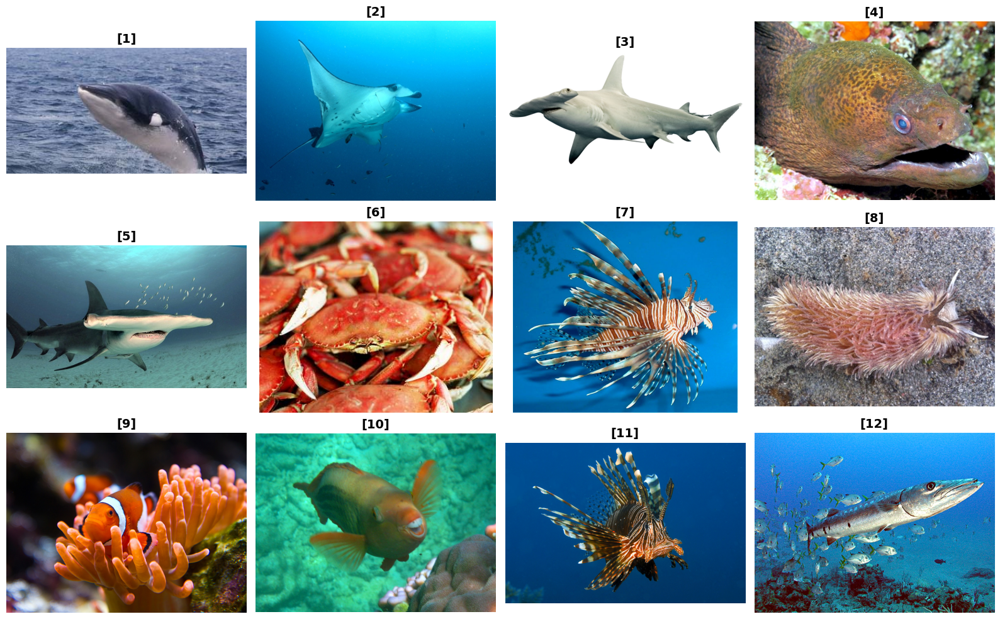

Pelabelan dihentikan.

===== HASIL PELABELAN =====
Total gambar dataset: 7990
Total gambar berlabel: 533
Belum dilabeli: 7457

Distribusi kelas:
label
Fish                      461
Other marine organisms     55
Crustaceans                10
Shark                       3
Octopuses                   2
Coral                       1
Sponges                     1
Name: count, dtype: int64

CSV tersimpan di: output_oceaniclife\oceaniclife_labels.csv


In [122]:

import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# ==========================================
# 1. PENGATURAN FOLDER
# ==========================================

DATASET_DIR = (
    r"C:\Users\User\OneDrive\Documents"
    r"\Klasifikasi Image Menggunakan CNN"
    r"\OceanicLife Dataset"
)

OUTPUT_DIR = "output_oceaniclife"
CSV_PATH = os.path.join(
    OUTPUT_DIR, "oceaniclife_labels.csv"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==========================================
# 2. DAFTAR KELAS
# ==========================================

class_names = {
    0: "Fish",
    1: "Coral",
    2: "Shark",
    3: "Octopuses",
    4: "Crustaceans",
    5: "Seaweed",
    6: "Sponges",
    7: "Other marine organisms"
}

# ==========================================
# 3. MEMBACA DATASET
# ==========================================

extensions = (
    ".jpg", ".jpeg", ".png",
    ".bmp", ".gif", ".webp"
)

image_paths = []

for root, dirs, filenames in os.walk(DATASET_DIR):
    for filename in filenames:
        if filename.lower().endswith(extensions):
            image_paths.append(
                os.path.join(root, filename)
            )

image_paths = sorted(image_paths)

print("Total gambar dataset:", len(image_paths))

if len(image_paths) == 0:
    raise FileNotFoundError(
        "Folder dataset tidak ditemukan atau kosong!"
    )

# ==========================================
# 4. MEMBACA CSV LAMA
# ==========================================

if os.path.exists(CSV_PATH):
    df = pd.read_csv(
        CSV_PATH,
        dtype={"label_id": "Int64"}
    )

    print("CSV lama berhasil dibaca:", len(df))

else:
    df = pd.DataFrame(columns=[
        "filepath", "filename", "label", "label_id"
    ])

# Pastikan kolom tersedia
for col in ["filepath", "filename", "label", "label_id"]:
    if col not in df.columns:
        df[col] = pd.NA

# ==========================================
# 5. MENCARI GAMBAR YANG BELUM DILABELI
# ==========================================

labeled_files = set(
    df.loc[
        df["label_id"].notna(),
        "filename"
    ].astype(str)
)

todo = [
    path for path in image_paths
    if os.path.basename(path) not in labeled_files
]

print("Sudah dilabeli:", len(labeled_files))
print("Belum dilabeli:", len(todo))

# ==========================================
# 6. PROSES PELABELAN
# ==========================================

batch_size = 12

for awal in range(0, len(todo), batch_size):

    batch = todo[awal:awal + batch_size]

    fig, axes = plt.subplots(
        3, 4, figsize=(16, 10)
    )

    for i, ax in enumerate(axes.flat):

        if i < len(batch):

            try:
                img = Image.open(batch[i])
                img = ImageOps.exif_transpose(img)
                img = img.convert("RGB")

                ax.imshow(img)

                ax.set_title(
                    f"[{i+1}]",
                    fontsize=14,
                    fontweight="bold"
                )

                ax.axis("off")

            except Exception as e:
                print("Gagal membaca:", batch[i])
                ax.axis("off")

        else:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

    # Input label
    while True:

        label = input(
            f"Label {len(batch)} gambar "
            "(mis. 004000077770; ':' = lewati; "
            "q = berhenti): "
        ).strip()

        if label.lower() == "q":
            print("Pelabelan dihentikan.")
            break

        if label == ":":
            print("Kelompok dilewati.")
            break

        if (
            len(label) != len(batch)
            or not label.isdigit()
        ):
            print(
                f"Masukkan tepat {len(batch)} angka!"
            )
            continue

        # Validasi kelas 0 sampai 7
        if any(int(x) not in class_names for x in label):
            print("Label hanya boleh menggunakan angka 0-7!")
            continue

        # Simpan label
        new_rows = []

        for i, path in enumerate(batch):

            label_id = int(label[i])

            new_rows.append({
                "filepath": path,
                "filename": os.path.basename(path),
                "label": class_names[label_id],
                "label_id": label_id
            })

        df = pd.concat(
            [df, pd.DataFrame(new_rows)],
            ignore_index=True
        )

        # Simpan setiap kelompok
        df.to_csv(CSV_PATH, index=False)

        print("Label berhasil disimpan:", label)
        print("Total gambar berlabel:", len(df))

        break

    if label.lower() == "q":
        break

# ==========================================
# 7. RINGKASAN HASIL
# ==========================================

df = pd.read_csv(CSV_PATH)

print("\n===== HASIL PELABELAN =====")
print("Total gambar dataset:", len(image_paths))
print("Total gambar berlabel:", len(df))
print("Belum dilabeli:", len(image_paths) - len(df))

print("\nDistribusi kelas:")

print(
    df["label"].value_counts()
)

print("\nCSV tersimpan di:", CSV_PATH)


In [123]:
import os
import pandas as pd

# Folder dataset
DATASET_DIR = r"C:\Users\User\OneDrive\Documents\Klasifikasi Image Menggunakan CNN\OceanicLife Dataset"

# Membaca semua gambar
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

image_paths = []

for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        if file.lower().endswith(extensions):
            image_paths.append(os.path.join(root, file))

# Nama file yang sudah dilabeli
labeled_files = set(df["filename"].astype(str))

# Cari gambar yang belum dilabeli
todo = [
    path for path in image_paths
    if os.path.basename(path) not in labeled_files
]

print("Total gambar:", len(image_paths))
print("Sudah dilabeli:", len(df))
print("Belum dilabeli:", len(todo))

print("\n10 gambar berikutnya:")
for path in todo[:10]:
    print(os.path.basename(path))

Total gambar: 7990
Sudah dilabeli: 533
Belum dilabeli: 7457

10 gambar berikutnya:
2joh6js2.jpg
2jss9g3g.jpg
2jwx9uyh.jpg
2k9ogtjl.jpg
2kejb37n.jpg
2kf1gk3y.jpg
2kfumecu.jpg
2kjof9wt.jpg
2kpotn6o.jpg
2krge9hx.jpg


In [124]:

import os
import pandas as pd

# Folder dataset
DATASET_DIR = r"C:\Users\User\OneDrive\Documents\Klasifikasi Image Menggunakan CNN\OceanicLife Dataset"

# File CSV
CSV_PATH = r"output_oceaniclife\oceaniclife_labels.csv"

# Daftar kelas
class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

label_mapping = {
    name: idx for idx, name in enumerate(class_names)
}

# Ambil seluruh gambar
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

image_files = []

for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        if file.lower().endswith(extensions):
            image_files.append(os.path.join(root, file))

# Baca CSV lama
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
else:
    df = pd.DataFrame(
        columns=["filepath", "filename", "label", "label_id"]
    )

# Pastikan nama kolom tersedia
df["filename"] = df["filename"].astype(str)

# Hanya pertahankan label yang valid
df = df[df["label"].isin(class_names)].copy()

df["label_id"] = df["label"].map(label_mapping)

# Hindari duplikasi berdasarkan path
labeled_paths = set(
    df["filepath"].astype(str).str.lower()
)

# Cari gambar yang belum dilabeli
todo = [
    path for path in image_files
    if path.lower() not in labeled_paths
]

print("Total gambar:", len(image_files))
print("Sudah dilabeli:", len(df))
print("Belum dilabeli:", len(todo))

print("\nDistribusi kelas:")
print(
    df["label"].value_counts()
    .reindex(class_names, fill_value=0)
)


Total gambar: 7990
Sudah dilabeli: 533
Belum dilabeli: 7857

Distribusi kelas:
label
Fish                      461
Coral                       1
Shark                       3
Octopuses                   2
Crustaceans                10
Seaweed                     0
Sponges                     1
Other marine organisms     55
Name: count, dtype: int64


In [125]:
import os
import pandas as pd

# Lokasi dataset
DATASET_DIR = r"C:\Users\User\OneDrive\Documents\Klasifikasi Image Menggunakan CNN\OceanicLife Dataset"

# Lokasi CSV
CSV_PATH = r"output_oceaniclife\oceaniclife_labels.csv"

# Daftar kelas
class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

label_mapping = {
    name: idx for idx, name in enumerate(class_names)
}

# Ambil semua gambar
extensions = (".jpg", ".jpeg", ".png", ".gif", ".bmp")

image_files = [
    f for f in os.listdir(DATASET_DIR)
    if f.lower().endswith(extensions)
]

# Baca CSV
df = pd.read_csv(CSV_PATH)

# Bersihkan data
df = df.dropna(subset=["filename", "label"])

df["filename"] = df["filename"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.strip()

# Pastikan label valid
df = df[df["label"].isin(class_names)]

# Hilangkan duplikat berdasarkan nama file
df = df.drop_duplicates(subset=["filename"], keep="last")

# Buat ulang label_id
df["label_id"] = df["label"].map(label_mapping)

# Simpan CSV
df.to_csv(CSV_PATH, index=False)

# Hitung data
labeled_files = set(df["filename"].str.lower())

unlabeled_files = [
    f for f in image_files
    if f.lower() not in labeled_files
]

print("TOTAL GAMBAR DATASET:", len(image_files))
print("SUDAH DILABELI:", len(df))
print("BELUM DILABELI:", len(unlabeled_files))

print("\nDISTRIBUSI KELAS:")
print(
    df["label"].value_counts()
    .reindex(class_names, fill_value=0)
)

print("\n10 GAMBAR BELUM DILABELI:")
print(unlabeled_files[:10])

TOTAL GAMBAR DATASET: 7990
SUDAH DILABELI: 533
BELUM DILABELI: 7457

DISTRIBUSI KELAS:
label
Fish                      461
Coral                       1
Shark                       3
Octopuses                   2
Crustaceans                10
Seaweed                     0
Sponges                     1
Other marine organisms     55
Name: count, dtype: int64

10 GAMBAR BELUM DILABELI:
['2joh6js2.jpg', '2jss9g3g.jpg', '2jwx9uyh.jpg', '2k9ogtjl.jpg', '2kejb37n.jpg', '2kf1gk3y.jpg', '2kfumecu.jpg', '2kjof9wt.jpg', '2kpotn6o.jpg', '2krge9hx.jpg']


In [ ]:
import os
import pandas as pd
from PIL import Image
from IPython.display import display, clear_output
import ipywidgets as widgets

# ==================================
# KONFIGURASI
# ==================================

DATASET_DIR = r"C:\Users\User\OneDrive\Documents\Klasifikasi Image Menggunakan CNN\OceanicLife Dataset"

CSV_PATH = r"output_oceaniclife\oceaniclife_labels.csv"

os.makedirs(os.path.dirname(CSV_PATH), exist_ok=True)

class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

label_mapping = {
    name: idx for idx, name in enumerate(class_names)
}

extensions = (".jpg", ".jpeg", ".png", ".gif", ".bmp")

# ==================================
# MEMBACA CSV LAMA
# ==================================

if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
else:
    df = pd.DataFrame(
        columns=["filepath", "filename", "label", "label_id"]
    )

# Pastikan kolom tersedia
for col in ["filepath", "filename", "label", "label_id"]:
    if col not in df.columns:
        df[col] = None

df = df.dropna(subset=["filename", "label"]).copy()

df["filename"] = df["filename"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.strip()

df = df[df["label"].isin(class_names)]
df = df.drop_duplicates(subset=["filename"], keep="last")

df["label_id"] = df["label"].map(label_mapping)

# ==================================
# MENGAMBIL GAMBAR BELUM DILABELI
# ==================================

image_files = [
    f for f in os.listdir(DATASET_DIR)
    if f.lower().endswith(extensions)
]

labeled_files = set(df["filename"].str.lower())

todo = [
    f for f in sorted(image_files)
    if f.lower() not in labeled_files
]

print("Total gambar:", len(image_files))
print("Sudah dilabeli:", len(df))
print("Belum dilabeli:", len(todo))

# ==================================
# TAMPILAN PELABELAN
# ==================================

index = 0

image_output = widgets.Output()

class_dropdown = widgets.Dropdown(
    options=class_names,
    description="Kelas:",
    layout=widgets.Layout(width="400px")
)

save_button = widgets.Button(
    description="Simpan Label",
    button_style="success"
)

skip_button = widgets.Button(
    description="Lewati",
    button_style="warning"
)

progress = widgets.Label()

def show_image():
    with image_output:
        clear_output(wait=True)

        if index >= len(todo):
            print("SEMUA GAMBAR SELESAI DILABELI!")
            return

        filename = todo[index]
        filepath = os.path.join(DATASET_DIR, filename)

        try:
            img = Image.open(filepath).convert("RGB")
            img.thumbnail((600, 450))
            display(img)

            print("Gambar:", filename)
            print("Progres:", index + 1, "/", len(todo))

        except Exception as e:
            print("Gagal membuka gambar:", e)

    progress.value = (
        f"Progres: {index + 1}/{len(todo)}"
    )

def save_label(b):
    global index, df

    if index >= len(todo):
        return

    filename = todo[index]
    filepath = os.path.join(DATASET_DIR, filename)
    label = class_dropdown.value

    new_row = pd.DataFrame([{
        "filepath": filepath,
        "filename": filename,
        "label": label,
        "label_id": label_mapping[label]
    }])

    df = pd.concat([df, new_row], ignore_index=True)

    df.to_csv(CSV_PATH, index=False)

    index += 1
    show_image()

def skip_image(b):
    global index

    if index < len(todo):
        index += 1
        show_image()

save_button.on_click(save_label)
skip_button.on_click(skip_image)

display(progress)
display(image_output)
display(class_dropdown)
display(widgets.HBox([save_button, skip_button]))

show_image()

Total gambar: 7990
Sudah dilabeli: 533
Belum dilabeli: 7457


Label(value='')

Output()

Dropdown(description='Kelas:', layout=Layout(width='400px'), options=('Fish', 'Coral', 'Shark', 'Octopuses', '…

In [127]:
import pandas as pd

df = pd.read_csv(
    r"output_oceaniclife\oceaniclife_labels.csv"
)

class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

print("TOTAL DATA:", len(df))

print("\nDISTRIBUSI KELAS:")

print(
    df["label"].value_counts()
    .reindex(class_names, fill_value=0)
)

print("\nJUMLAH KELAS:", df["label"].nunique())

TOTAL DATA: 630

DISTRIBUSI KELAS:
label
Fish                      558
Coral                       1
Shark                       3
Octopuses                   2
Crustaceans                10
Seaweed                     0
Sponges                     1
Other marine organisms     55
Name: count, dtype: int64

JUMLAH KELAS: 7


In [130]:
import ssl
try:
    import certifi
    os.environ["SSL_CERT_FILE"] = certifi.where()
    os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()
    ssl._create_default_https_context = lambda *a, **k: ssl.create_default_context(
        cafile=certifi.where()
    )
except ImportError:
    pass

augment = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")

# ---- Base model pretrained ----
try:
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,),
        include_top=False,
        weights=WEIGHTS
    )
except Exception as e:
    raise RuntimeError(
        "Gagal mengunduh bobot ImageNet. Cek koneksi internet, atau set WEIGHTS = None "
        "(akurasi akan lebih rendah)."
    ) from e

base_model.trainable = False

# ----- Susun model -----
inputs = layers.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = layers.Rescaling(1. / 127.5, offset=-1, name="rescale")(x)   # skala [-1, 1] sesuai MobileNetV2
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="head"
)(x)

model = models.Model(inputs, outputs, name="oceaniclife_mobilenetv2")
model.compile(
    optimizer=Adam(1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "oceaniclife_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Dense)                    │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [131]:
os.makedirs(OUT_DIR, exist_ok=True)

In [133]:
required_vars = [
    "os",
    "time",
    "model",
    "base_model",
    "train_ds",
    "val_ds",
    "class_weight",
    "EPOCHS",
    "FINE_TUNE_EPOCHS",
    "OUT_DIR",
    "EarlyStopping",
    "ModelCheckpoint",
    "ReduceLROnPlateau",
    "Adam"
]

for var in required_vars:
    print(var, ":", var in globals())

os : True
time : True
model : True
base_model : True
train_ds : False
val_ds : False
class_weight : False
EPOCHS : True
FINE_TUNE_EPOCHS : True
OUT_DIR : True
EarlyStopping : True
ModelCheckpoint : True
ReduceLROnPlateau : True
Adam : True


In [135]:
print("=== CEK KONDISI NOTEBOOK ===")

variables = [
    "model",
    "base_model",
    "train_ds",
    "val_ds",
    "class_weight",
    "EPOCHS",
    "FINE_TUNE_EPOCHS",
    "OUT_DIR",
    "os",
    "time",
    "Adam",
    "EarlyStopping",
    "ModelCheckpoint",
    "ReduceLROnPlateau"
]

for v in variables:
    print(f"{v}: {'ADA' if v in globals() else 'BELUM ADA'}")

print("\n=== CEK MODEL ===")

if "model" in globals():
    model.summary()

print("\n=== SELESAI ===")

=== CEK KONDISI NOTEBOOK ===
model: ADA
base_model: ADA
train_ds: BELUM ADA
val_ds: BELUM ADA
class_weight: BELUM ADA
EPOCHS: ADA
FINE_TUNE_EPOCHS: ADA
OUT_DIR: ADA
os: ADA
time: ADA
Adam: ADA
EarlyStopping: ADA
ModelCheckpoint: ADA
ReduceLROnPlateau: ADA

=== CEK MODEL ===


Model: "oceaniclife_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Dense)                    │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


=== SELESAI ===


In [136]:
print("STATUS MODEL:", "model" in globals())
print("STATUS BASE MODEL:", "base_model" in globals())
print("STATUS TRAIN:", "train_ds" in globals())
print("STATUS VALIDATION:", "val_ds" in globals())
print("STATUS CLASS WEIGHT:", "class_weight" in globals())

if "model" in globals():
    print("\nMODEL SIAP")
    print("Output model:", model.output_shape)

if "train_ds" in globals():
    print("Jumlah batch training:", len(train_ds))

if "val_ds" in globals():
    print("Jumlah batch validation:", len(val_ds))

STATUS MODEL: True
STATUS BASE MODEL: True
STATUS TRAIN: False
STATUS VALIDATION: False
STATUS CLASS WEIGHT: False

MODEL SIAP
Output model: (None, 8)


In [138]:
import os
import pandas as pd

OUT_DIR = "output_oceaniclife"
CSV_PATH = os.path.join(OUT_DIR, "oceaniclife_labels.csv")

df = pd.read_csv(CSV_PATH)

print("TOTAL DATA:", len(df))
print("\nKOLOM:", df.columns.tolist())

print("\nDISTRIBUSI KELAS:")
print(df["label"].value_counts())

print("\nCEK PATH:")
print("Path tersedia:", df["filepath"].notna().sum())
print("File ditemukan:", df["filepath"].apply(
    lambda x: os.path.exists(str(x))
).sum())

TOTAL DATA: 630

KOLOM: ['filepath', 'filename', 'label', 'label_id']

DISTRIBUSI KELAS:
label
Fish                      558
Other marine organisms     55
Crustaceans                10
Shark                       3
Octopuses                   2
Coral                       1
Sponges                     1
Name: count, dtype: int64

CEK PATH:
Path tersedia: 230
File ditemukan: 230


In [139]:
import os
import pandas as pd

OUT_DIR = "output_oceaniclife"
CSV_PATH = os.path.join(OUT_DIR, "oceaniclife_labels.csv")

df = pd.read_csv(CSV_PATH)

print("TOTAL DATA:", len(df))
print("\nKOLOM:", df.columns.tolist())

print("\nDISTRIBUSI KELAS:")
print(df["label"].value_counts())

print("\nCEK PATH:")
print("Path tersedia:", df["filepath"].notna().sum())
print("File ditemukan:", df["filepath"].apply(
    lambda x: os.path.exists(str(x))
).sum())

TOTAL DATA: 630

KOLOM: ['filepath', 'filename', 'label', 'label_id']

DISTRIBUSI KELAS:
label
Fish                      558
Other marine organisms     55
Crustaceans                10
Shark                       3
Octopuses                   2
Coral                       1
Sponges                     1
Name: count, dtype: int64

CEK PATH:
Path tersedia: 230
File ditemukan: 230


In [140]:
import os
import pandas as pd

# Lokasi dataset
DATASET_DIR = r"C:\Users\User\OneDrive\Documents\Klasifikasi Image Menggunakan CNN\OceanicLife Dataset"

# Pastikan dataframe tersedia
assert 'df' in globals(), "DataFrame df belum tersedia"

# Buat indeks seluruh gambar berdasarkan nama file
file_index = {}

for root, dirs, files in os.walk(DATASET_DIR):
    for filename in files:
        file_index[filename.lower()] = os.path.join(root, filename)

# Perbaiki filepath berdasarkan filename
df['filepath'] = df['filename'].apply(
    lambda x: file_index.get(str(x).lower())
)

# Periksa hasil
df['file_exists'] = df['filepath'].apply(
    lambda x: isinstance(x, str) and os.path.isfile(x)
)

print("===== HASIL PERBAIKAN PATH =====")
print("Total data:", len(df))
print("Path berhasil ditemukan:", df['file_exists'].sum())
print("Path tidak ditemukan:", (~df['file_exists']).sum())

print("\nContoh hasil:")
display(df[['filename', 'filepath', 'file_exists']].head(10))

===== HASIL PERBAIKAN PATH =====
Total data: 630
Path berhasil ditemukan: 630
Path tidak ditemukan: 0

Contoh hasil:


,filename,filepath,file_exists
0,001v5h0d.jpg,C:\Users\User\OneDrive\Documents\Klasifikasi I...,True
1,002ojjl6.jpg,C:\Users\User\OneDrive\Documents\Klasifikasi I...,True
2,00dx9zud.JPG,C:\Users\User\OneDrive\Documents\Klasifikasi I...,True
3,00gohyw5.jpg,C:\Users\User\OneDrive\Documents\Klasifikasi I...,True
4,00lvn4tu.gif,C:\Users\User\OneDrive\Documents\Klasifikasi I...,True
5,015e0ase.jpg,C:\Users\User\OneDrive\Documents\Klasifikasi I...,True
6,015us06k.jpg,C:\Users\User\OneDrive\Documents\Klasifikasi I...,True
7,017s6334.jpeg,C:\Users\User\OneDrive\Documents\Klasifikasi I...,True
8,01cqbman.jpg,C:\Users\User\OneDrive\Documents\Klasifikasi I...,True
9,01fifu6i.jpg,C:\Users\User\OneDrive\Documents\Klasifikasi I...,True


In [141]:
# ==========================================
# PEMERIKSAAN KESIAPAN DATASET
# ==========================================

import pandas as pd
import os

# Pastikan dataframe tersedia
assert 'df' in globals(), "DataFrame df belum tersedia"

# Pastikan kolom tersedia
required_cols = ['filepath', 'filename', 'label', 'label_id']

for col in required_cols:
    assert col in df.columns, f"Kolom {col} tidak ditemukan"

# Periksa path
df['file_exists'] = df['filepath'].apply(os.path.isfile)

print("TOTAL DATA:", len(df))
print("FILE DITEMUKAN:", df['file_exists'].sum())
print("FILE HILANG:", (~df['file_exists']).sum())

# Distribusi kelas
print("\nDISTRIBUSI KELAS:")
print(df['label'].value_counts())

# Periksa label kosong
print("\nLABEL KOSONG:")
print(df['label'].isna().sum())

# Periksa duplikat
print("\nDUPLIKAT FILENAME:")
print(df['filename'].duplicated().sum())

# Status
if df['file_exists'].all() and df['label'].notna().all():
    print("\nPEMERIKSAAN PATH DAN LABEL BERHASIL.")
else:
    print("\nDATA MASIH PERLU DIPERBAIKI.")

TOTAL DATA: 630
FILE DITEMUKAN: 630
FILE HILANG: 0

DISTRIBUSI KELAS:
label
Fish                      558
Other marine organisms     55
Crustaceans                10
Shark                       3
Octopuses                   2
Coral                       1
Sponges                     1
Name: count, dtype: int64

LABEL KOSONG:
0

DUPLIKAT FILENAME:
0

PEMERIKSAAN PATH DAN LABEL BERHASIL.


In [144]:
# ==========================================
# SPLIT DATASET 70:15:15
# VERSI AMAN
# ==========================================

import os
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

# Bersihkan dataset
data = df.copy()

data = data.dropna(subset=['filepath', 'label', 'label_id'])
data = data[data['filepath'].apply(os.path.isfile)].copy()

# Ambil kelas yang memiliki minimal 3 gambar
counts = data['label'].value_counts()
valid_classes = counts[counts >= 3].index

data = data[data['label'].isin(valid_classes)].copy()

print("Jumlah data:", len(data))
print("\nDistribusi kelas:")
print(data['label'].value_counts())

# Split pertama: 70% training, 30% sementara
tr_df, temp_df = train_test_split(
    data,
    test_size=0.30,
    random_state=SEED,
    stratify=data['label']
)

# Split kedua TANPA stratify
va_df, te_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED
)

# Reset index
tr_df = tr_df.reset_index(drop=True)
va_df = va_df.reset_index(drop=True)
te_df = te_df.reset_index(drop=True)

# Hasil
print("\n========== HASIL SPLIT ==========")
print("Training   :", len(tr_df))
print("Validation :", len(va_df))
print("Testing    :", len(te_df))
print("Total      :", len(tr_df) + len(va_df) + len(te_df))

print("\nDistribusi Training:")
print(tr_df['label'].value_counts())

print("\nDistribusi Validation:")
print(va_df['label'].value_counts())

print("\nDistribusi Testing:")
print(te_df['label'].value_counts())

print("\nSPLIT DATASET BERHASIL!")

Jumlah data: 626

Distribusi kelas:
label
Fish                      558
Other marine organisms     55
Crustaceans                10
Shark                       3
Name: count, dtype: int64

========== HASIL SPLIT ==========
Training   : 438
Validation : 94
Testing    : 94
Total      : 626

Distribusi Training:
label
Fish                      390
Other marine organisms     39
Crustaceans                 7
Shark                       2
Name: count, dtype: int64

Distribusi Validation:
label
Fish                      82
Other marine organisms    11
Crustaceans                1
Name: count, dtype: int64

Distribusi Testing:
label
Fish                      86
Other marine organisms     5
Crustaceans                2
Shark                      1
Name: count, dtype: int64

SPLIT DATASET BERHASIL!


In [147]:

# ==========================================
# SPLIT DATASET 70:15:15
# VERSI FINAL - MENGHINDARI ERROR
# ==========================================

import os
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

# 1. Bersihkan dataset
data = df.copy()

data = data.dropna(
    subset=['filepath', 'label', 'label_id']
).copy()

data = data[
    data['filepath'].apply(os.path.isfile)
].copy()

# 2. Pilih kelas minimal 3 gambar
counts = data['label'].value_counts()
valid_classes = counts[counts >= 3].index

data = data[
    data['label'].isin(valid_classes)
].copy()

print("DISTRIBUSI DATA:")
print(data['label'].value_counts())

# 3. Split training 70%
tr_df, temp_df = train_test_split(
    data,
    test_size=0.30,
    random_state=SEED,
    stratify=data['label']
)

# 4. Split validation dan testing
va_df, te_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED
)

# 5. Reset index
tr_df = tr_df.reset_index(drop=True)
va_df = va_df.reset_index(drop=True)
te_df = te_df.reset_index(drop=True)

# 6. Hasil split
print("\n========== HASIL SPLIT ==========")
print("Training   :", len(tr_df))
print("Validation :", len(va_df))
print("Testing    :", len(te_df))
print("Total      :", len(data))

print("\nDistribusi Training:")
print(tr_df['label'].value_counts())

print("\nDistribusi Validation:")
print(va_df['label'].value_counts())

print("\nDistribusi Testing:")
print(te_df['label'].value_counts())

# 7. Simpan hasil split
tr_df.to_csv(
    'output_oceaniclife/train.csv', index=False
)
va_df.to_csv(
    'output_oceaniclife/validation.csv', index=False
)
te_df.to_csv(
    'output_oceaniclife/test.csv', index=False
)

print("\nSPLIT DATASET BERHASIL!")


DISTRIBUSI DATA:
label
Fish                      558
Other marine organisms     55
Crustaceans                10
Shark                       3
Name: count, dtype: int64

========== HASIL SPLIT ==========
Training   : 438
Validation : 94
Testing    : 94
Total      : 626

Distribusi Training:
label
Fish                      390
Other marine organisms     39
Crustaceans                 7
Shark                       2
Name: count, dtype: int64

Distribusi Validation:
label
Fish                      82
Other marine organisms    11
Crustaceans                1
Name: count, dtype: int64

Distribusi Testing:
label
Fish                      86
Other marine organisms     5
Crustaceans                2
Shark                      1
Name: count, dtype: int64

SPLIT DATASET BERHASIL!


In [148]:

# ==========================================
# PREPROCESSING DATASET
# ==========================================

import tensorflow as tf
import numpy as np
import os
from PIL import Image

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

# Pastikan dataset tersedia
print("Training:", len(tr_df))
print("Validation:", len(va_df))
print("Testing:", len(te_df))

# Fungsi membaca gambar
def load_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label

# Membuat dataset TensorFlow
def create_dataset(dataframe, shuffle=False):
    paths = dataframe['filepath'].astype(str).values
    labels = dataframe['label_id'].astype('int32').values

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=SEED
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

train_ds = create_dataset(tr_df, shuffle=True)
val_ds = create_dataset(va_df)
test_ds = create_dataset(te_df)

print("\nPREPROCESSING BERHASIL!")
print("Train batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Test batches:", len(test_ds))


Training: 438
Validation: 94
Testing: 94

PREPROCESSING BERHASIL!
Train batches: 14
Validation batches: 3
Test batches: 3


In [149]:
print("Jumlah kelas:", len(class_names))
print("Nama kelas:", class_names)

print("Output model:", model.output_shape)

Jumlah kelas: 8
Nama kelas: ['Fish', 'Coral', 'Shark', 'Octopuses', 'Crustaceans', 'Seaweed', 'Sponges', 'Other marine organisms']
Output model: (None, 8)


In [151]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Pastikan data training tersedia
print("Jumlah data training:", len(tr_df))

# Ambil label dari data training
classes = np.unique(tr_df['label_id'])

# Hitung bobot setiap kelas
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=tr_df['label_id'].values
)

# Buat dictionary class_weight
class_weight = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class Weight berhasil dibuat:")
print(class_weight)


Jumlah data training: 438
Class Weight berhasil dibuat:
{0: 0.28076923076923077, 2: 54.75, 4: 15.642857142857142, 7: 2.8076923076923075}


In [153]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=['accuracy']
)

print("Model berhasil di-compile ulang!")

Model berhasil di-compile ulang!


In [154]:
for images, labels in train_ds.take(1):
    print("Shape gambar:", images.shape)
    print("Shape label:", labels.shape)
    print("Contoh label:", labels.numpy())
    print("Shape output model:", model.output_shape)

Shape gambar: (32, 160, 160, 3)
Shape label: (32,)
Contoh label: [0 0 0 7 0 0 0 0 4 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 7 0 0 0]
Shape output model: (None, 8)


In [155]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        os.path.join(OUT_DIR, 'best_model.keras'),
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7
    )
]

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weight
)

print("Training selesai!")

print(
    "Waktu training:",
    round((time.time() - start_time) / 60, 2),
    "menit"
)

Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 9s 355ms/step - accuracy: 0.0845 - loss: 2.3343 - val_accuracy: 0.0851 - val_loss: 2.2470 - learning_rate: 1.0000e-04
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 265ms/step - accuracy: 0.1712 - loss: 1.8786 - val_accuracy: 0.2447 - val_loss: 1.8895 - learning_rate: 1.0000e-04
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 251ms/step - accuracy: 0.2580 - loss: 1.8159 - val_accuracy: 0.3191 - val_loss: 1.6548 - learning_rate: 1.0000e-04
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 238ms/step - accuracy: 0.3470 - loss: 1.8321 - val_accuracy: 0.3936 - val_loss: 1.5000 - learning_rate: 1.0000e-04
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 233ms/step - accuracy: 0.3836 - loss: 1.5796 - val_accuracy: 0.4574 - val_loss: 1.3846 - learning_rate: 1.0000e-04
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 251ms/step - accuracy: 0.4178 - loss: 1.3721 - val_accuracy: 0.4787 - val_loss: 1.3131 - learning_rate: 1.0000e-04
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 218ms/step - accuracy: 

In [157]:
print("Training accuracy terakhir:",
      history.history['accuracy'][-1])

print("Validation accuracy terakhir:",
      history.history['val_accuracy'][-1])

print("Training loss terakhir:",
      history.history['loss'][-1])

print("Validation loss terakhir:",
      history.history['val_loss'][-1])

Training accuracy terakhir: 0.48630136251449585
Validation accuracy terakhir: 0.5
Training loss terakhir: 1.106916069984436
Validation loss terakhir: 1.0416066646575928


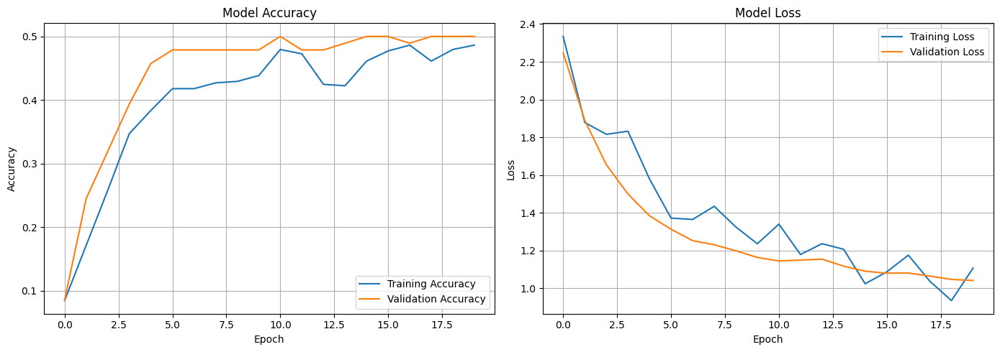

In [158]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [159]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", round(test_accuracy * 100, 2), "%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 139ms/step - accuracy: 0.4894 - loss: 1.0269
Test Loss: 1.0269192457199097
Test Accuracy: 0.4893617033958435
Test Accuracy (%): 48.94 %


3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 519ms/step
                        precision    recall  f1-score   support

                  Fish       0.93      0.48      0.63        86
                 Coral       0.00      0.00      0.00         0
                 Shark       0.00      0.00      0.00         1
             Octopuses       0.00      0.00      0.00         0
           Crustaceans       0.06      0.50      0.10         2
               Seaweed       0.00      0.00      0.00         0
               Sponges       0.00      0.00      0.00         0
Other marine organisms       0.13      0.80      0.22         5

              accuracy                           0.49        94
             macro avg       0.14      0.22      0.12        94
          weighted avg       0.86      0.49      0.59        94



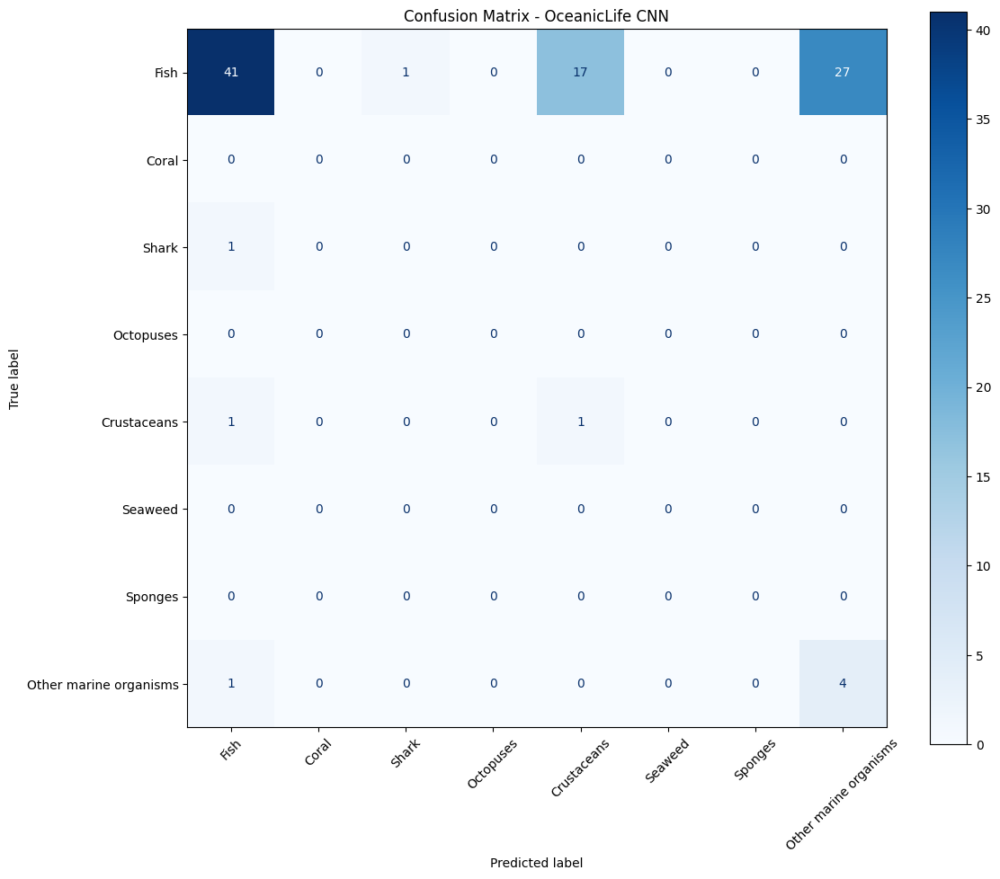

In [160]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred = np.argmax(
    model.predict(test_ds),
    axis=1
)

class_names = [
    'Fish',
    'Coral',
    'Shark',
    'Octopuses',
    'Crustaceans',
    'Seaweed',
    'Sponges',
    'Other marine organisms'
]

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(8)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(8))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.title('Confusion Matrix - OceanicLife CNN')
plt.tight_layout()
plt.show()

In [161]:
model.save(
    os.path.join(OUT_DIR, 'oceaniclife_cnn_final.keras')
)

print("Model berhasil disimpan!")

Model berhasil disimpan!


In [162]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

class_names = [
    'Fish',
    'Coral',
    'Shark',
    'Octopuses',
    'Crustaceans',
    'Seaweed',
    'Sponges',
    'Other marine organisms'
]

def predict_image(image_path):

    img = Image.open(image_path).convert('RGB')
    img = img.resize((160, 160))

    img_array = np.array(img, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)

    predictions = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(predictions[0])
    confidence = predictions[0][predicted_index] * 100

    plt.figure(figsize=(6, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.title(
        f'{class_names[predicted_index]} ({confidence:.2f}%)'
    )
    plt.show()

    print("Hasil Prediksi:", class_names[predicted_index])
    print("Confidence:", round(confidence, 2), "%")

    return predictions

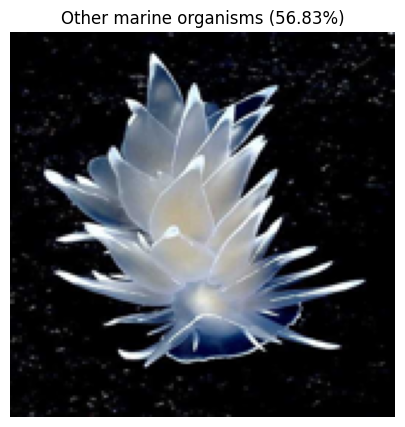

Hasil Prediksi: Other marine organisms
Confidence: 56.83 %


array([[1.9823980e-01, 4.4327640e-04, 1.4893946e-01, 5.0658551e-03,
        7.2153747e-02, 5.5038128e-03, 1.3723552e-03, 5.6828165e-01]],
      dtype=float32)

In [163]:
predict_image(
    r'C:\Users\User\OneDrive\Documents\Klasifikasi Image Menggunakan CNN\OceanicLife Dataset\001v5h0d.jpg'
)

In [164]:
import json
import os

model.save(
    os.path.join(OUT_DIR, 'oceaniclife_cnn_final.keras')
)

with open(
    os.path.join(OUT_DIR, 'class_names.json'),
    'w'
) as f:
    json.dump(class_names, f, indent=4)

print("Model dan nama kelas berhasil disimpan!")

Model dan nama kelas berhasil disimpan!
